In [9]:
# Graph-Based Predictive Analytics for Student Performance

## Project Overview

#This project develops a graph-based predictive analytics framework
#for analyzing relationships among students and predicting academic
#performance using graph analytics and machine learning.

In [10]:
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [11]:
# Display all column names
print("Column names in the dataset:")
print(df.columns.tolist())

print("\nNumber of columns:", len(df.columns))
print("Number of rows:", len(df))

Column names in the dataset:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Number of columns: 33
Number of rows: 395


In [12]:
# Check data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [13]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


In [14]:
# Statistical summary of numerical variables
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set a clean plotting style
sns.set_theme(style="whitegrid")

print("Visualization libraries loaded successfully!")

Visualization libraries loaded successfully!


In [16]:
print("Final Grade (G3) Summary")
print("------------------------")
print(df["G3"].describe())

print("\nUnique G3 values:")
print(sorted(df["G3"].unique()))

Final Grade (G3) Summary
------------------------
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Unique G3 values:
[np.int64(0), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


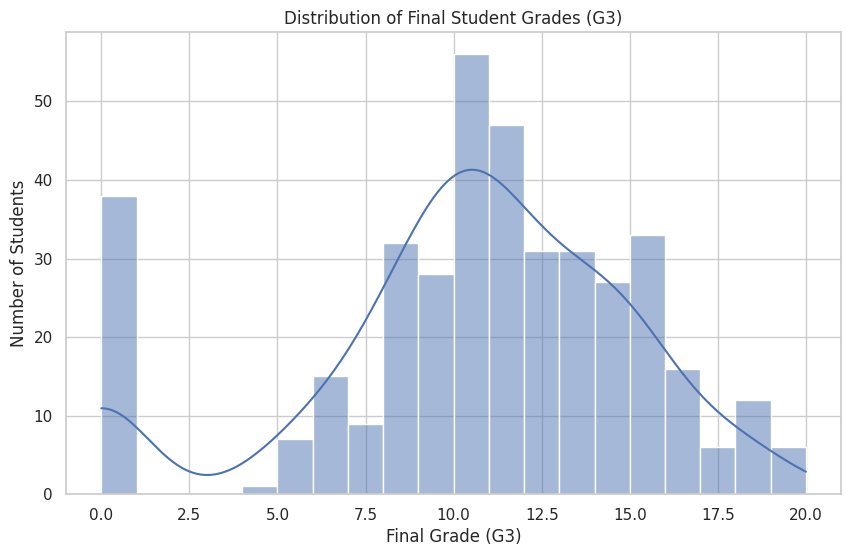

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="G3",
    bins=20,
    kde=True
)

plt.title("Distribution of Final Student Grades (G3)")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

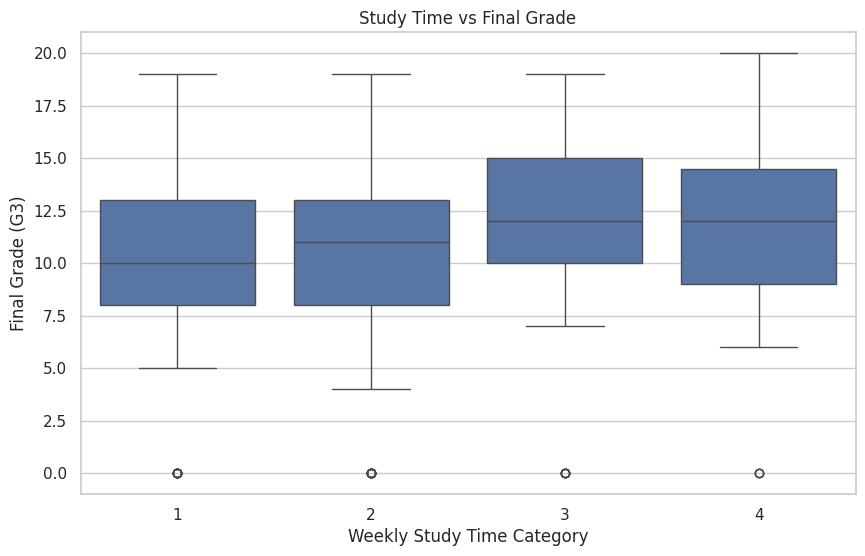

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade (G3)")

plt.show()

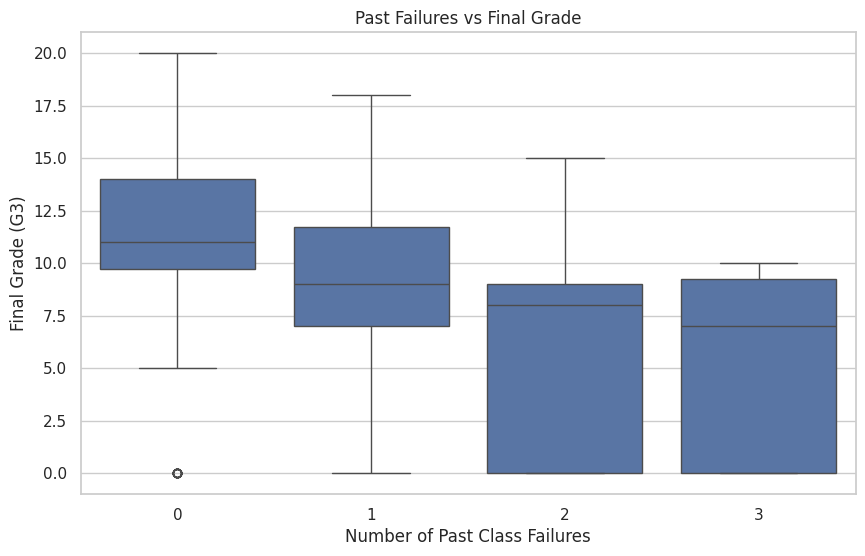

In [19]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="failures",
    y="G3"
)

plt.title("Past Failures vs Final Grade")
plt.xlabel("Number of Past Class Failures")
plt.ylabel("Final Grade (G3)")

plt.show()

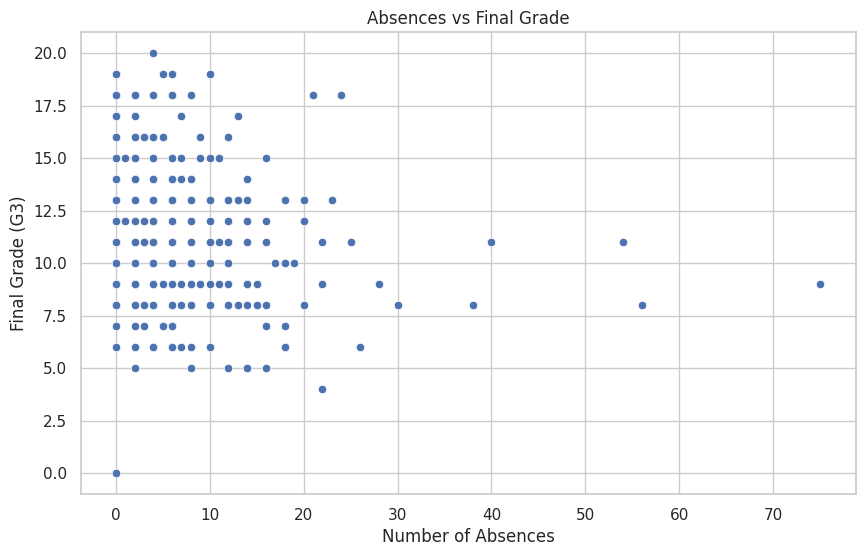

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.show()

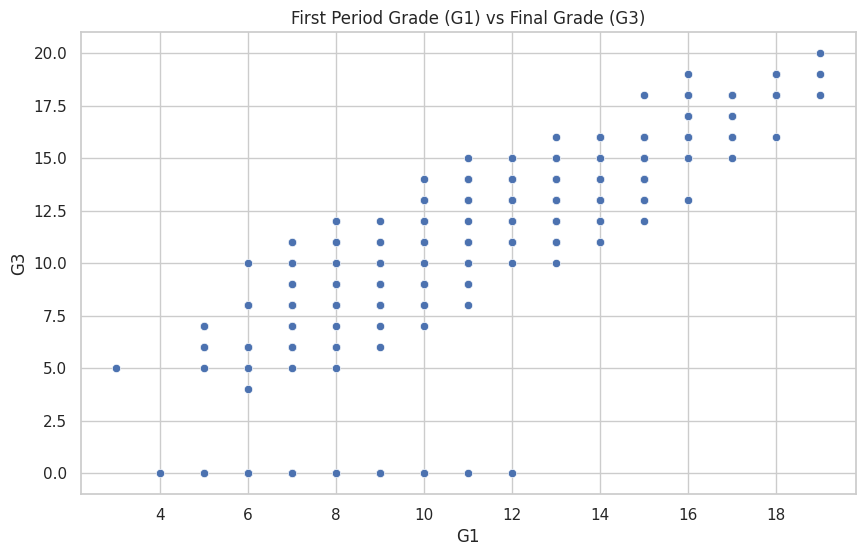

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="G1",
    y="G3"
)

plt.title("First Period Grade (G1) vs Final Grade (G3)")
plt.xlabel("G1")
plt.ylabel("G3")

plt.show()

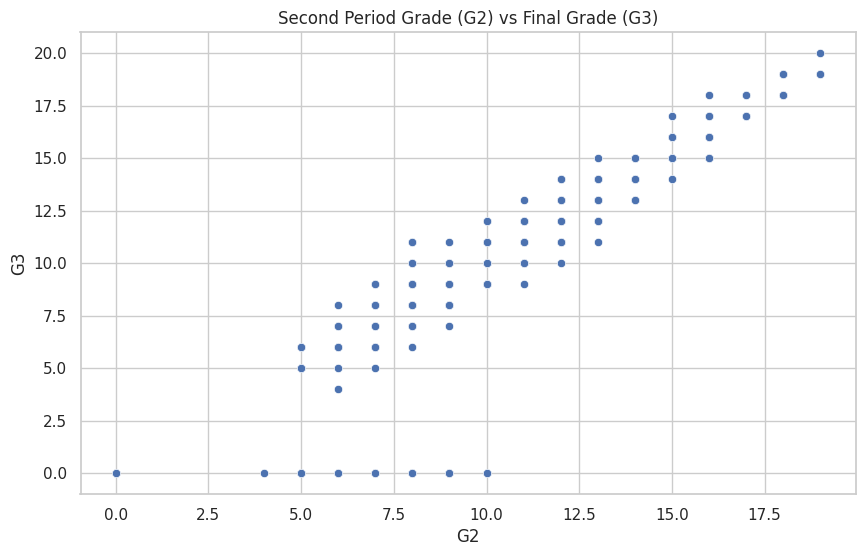

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="G2",
    y="G3"
)

plt.title("Second Period Grade (G2) vs Final Grade (G3)")
plt.xlabel("G2")
plt.ylabel("G3")

plt.show()

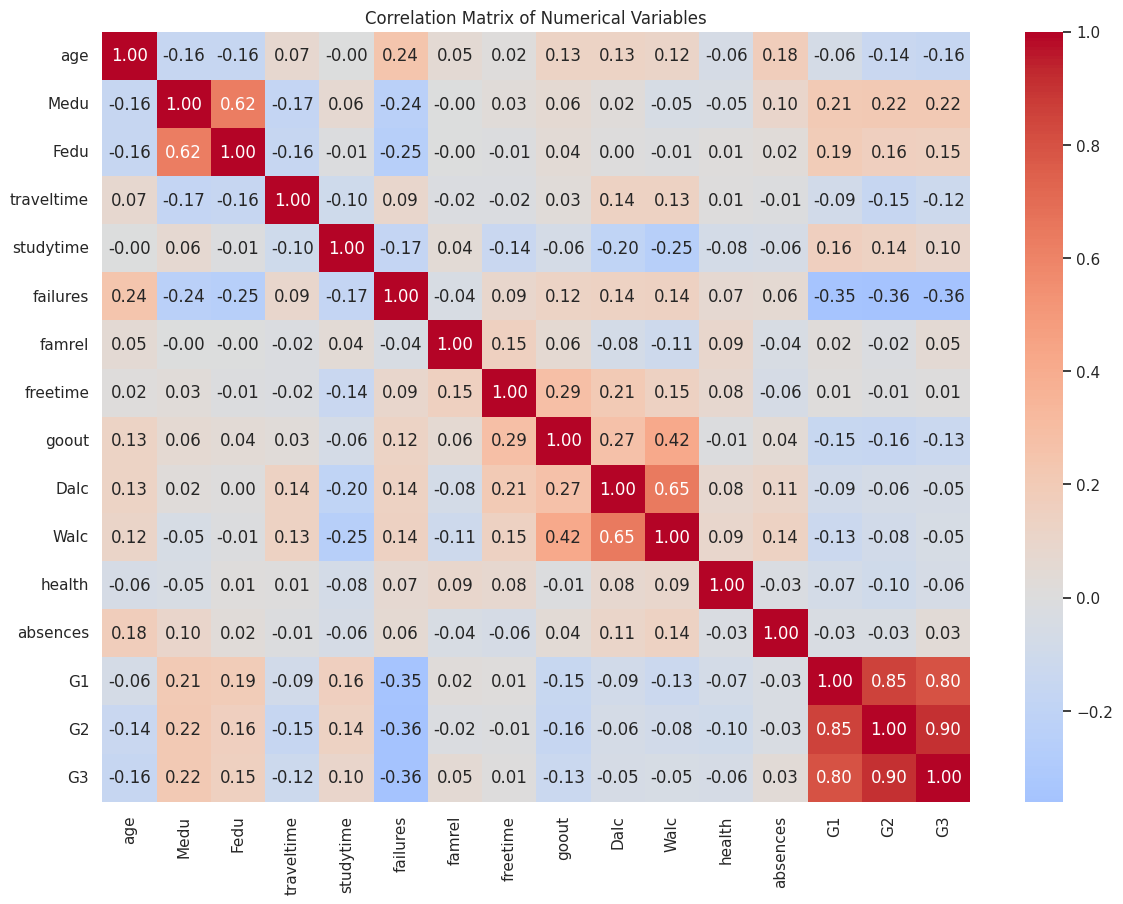

In [23]:
numeric_columns = [
    "age",
    "Medu",
    "Fedu",
    "traveltime",
    "studytime",
    "failures",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health",
    "absences",
    "G1",
    "G2",
    "G3"
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

In [24]:
# Features used to construct the student similarity graph
graph_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

graph_df = df[graph_features].copy()

print("Graph feature dataset:")
print(graph_df.head())

print("\nShape:", graph_df.shape)

Graph feature dataset:
   age  studytime  failures  absences  G1  G2
0   18          2         0         6   5   6
1   17          2         0         4   5   5
2   15          2         3        10   7   8
3   15          3         0         2  15  14
4   16          2         0         4   6  10

Shape: (395, 6)


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

graph_features_scaled = scaler.fit_transform(graph_df)

graph_scaled_df = pd.DataFrame(
    graph_features_scaled,
    columns=graph_features,
    index=df.index
)

print("Standardized graph features:")
display(graph_scaled_df.head())

Standardized graph features:


,age,studytime,failures,absences,G1,G2
0,1.023046,-0.042286,-0.449944,0.036424,-1.782467,-1.254791
1,0.238380,-0.042286,-0.449944,-0.213796,-1.782467,-1.520979
2,-1.330954,-0.042286,3.589323,0.536865,-1.179147,-0.722415
3,-1.330954,1.150779,-0.449944,-0.464016,1.234133,0.874715
4,-0.546287,-0.042286,-0.449944,-0.213796,-1.480807,-0.190038


In [26]:
graph_scaled_df["student_id"] = [
    f"S{i+1:03d}" for i in range(len(graph_scaled_df))
]

print(graph_scaled_df.head())

        age  studytime  failures  absences        G1        G2 student_id
0  1.023046  -0.042286 -0.449944  0.036424 -1.782467 -1.254791       S001
1  0.238380  -0.042286 -0.449944 -0.213796 -1.782467 -1.520979       S002
2 -1.330954  -0.042286  3.589323  0.536865 -1.179147 -0.722415       S003
3 -1.330954   1.150779 -0.449944 -0.464016  1.234133  0.874715       S004
4 -0.546287  -0.042286 -0.449944 -0.213796 -1.480807 -0.190038       S005


In [27]:
target_df = df[["G3"]].copy()

target_df["student_id"] = [
    f"S{i+1:03d}" for i in range(len(target_df))
]

print(target_df.head())

   G3 student_id
0   6       S001
1   6       S002
2  10       S003
3  15       S004
4  10       S005


In [28]:
# Graph and machine-learning libraries

import networkx as nx
from sklearn.neighbors import NearestNeighbors

print("NetworkX version:", nx.__version__)
print("Graph libraries loaded successfully!")

NetworkX version: 3.7
Graph libraries loaded successfully!


In [29]:
# Number of nearest neighbors
K = 5

# Use only the standardized numerical graph features
X_graph = graph_scaled_df[graph_features].values

# Find K+1 neighbors because the first neighbor is the student itself
knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="euclidean"
)

knn.fit(X_graph)

distances, indices = knn.kneighbors(X_graph)

print("K =", K)
print("Distance matrix shape:", distances.shape)
print("Neighbor index matrix shape:", indices.shape)

K = 5
Distance matrix shape: (395, 6)
Neighbor index matrix shape: (395, 6)


In [30]:
# Examine the nearest neighbors of the first student

student_index = 0

print("Student:", graph_scaled_df.iloc[student_index]["student_id"])
print("\nNearest students:")

for rank in range(1, K + 1):
    neighbor_index = indices[student_index][rank]
    distance = distances[student_index][rank]
    neighbor_id = graph_scaled_df.iloc[neighbor_index]["student_id"]

    print(
        f"{rank}. {neighbor_id} "
        f"| Distance = {distance:.3f}"
    )

Student: S001

Nearest students:
1. S002 | Distance = 0.866
2. S008 | Distance = 0.882
3. S178 | Distance = 0.917
4. S221 | Distance = 0.978
5. S262 | Distance = 1.163


In [31]:
# Create an undirected student similarity graph
G = nx.Graph()

# Add all students as nodes
for student_id in graph_scaled_df["student_id"]:
    G.add_node(student_id)

# Add edges between each student and their K nearest neighbors
for i in range(len(graph_scaled_df)):

    student_id = graph_scaled_df.iloc[i]["student_id"]

    for rank in range(1, K + 1):

        neighbor_index = indices[i][rank]
        neighbor_id = graph_scaled_df.iloc[neighbor_index]["student_id"]

        distance = distances[i][rank]

        # Convert distance to similarity
        similarity = 1 / (1 + distance)

        # Add edge
        G.add_edge(
            student_id,
            neighbor_id,
            distance=distance,
            similarity=similarity
        )

print("Graph created successfully!")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Graph created successfully!
Number of nodes: 395
Number of edges: 1310


In [32]:
print("----- STUDENT SIMILARITY GRAPH -----")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

print("\nIs graph connected?:", nx.is_connected(G))
print("Number of connected components:", nx.number_connected_components(G))

----- STUDENT SIMILARITY GRAPH -----
Nodes: 395
Edges: 1310
Density: 0.016834800488337725

Is graph connected?: True
Number of connected components: 1


In [33]:
# Display the first 10 edges with their weights

edge_data = list(G.edges(data=True))

for edge in edge_data[:10]:
    print(edge)

('S001', 'S002', {'distance': np.float64(0.8655450077559443), 'similarity': np.float64(0.5360363839213376)})
('S001', 'S008', {'distance': np.float64(0.8817917811510915), 'similarity': np.float64(0.5314084214929987)})
('S001', 'S178', {'distance': np.float64(0.9166061913396337), 'similarity': np.float64(0.5217555930470196)})
('S001', 'S221', {'distance': np.float64(0.9783359522248469), 'similarity': np.float64(0.5054753207489329)})
('S001', 'S262', {'distance': np.float64(1.1631225556443163), 'similarity': np.float64(0.46229465704135103)})
('S001', 'S249', {'distance': np.float64(1.5199717952645826), 'similarity': np.float64(0.39682983828595025)})
('S001', 'S382', {'distance': np.float64(1.3427775259250365), 'similarity': np.float64(0.42684377365501397)})
('S001', 'S387', {'distance': np.float64(1.2652712769017889), 'similarity': np.float64(0.4414482319167088)})
('S002', 'S178', {'distance': np.float64(0.3016599899736647), 'similarity': np.float64(0.7682497792839373)})
('S002', 'S008',

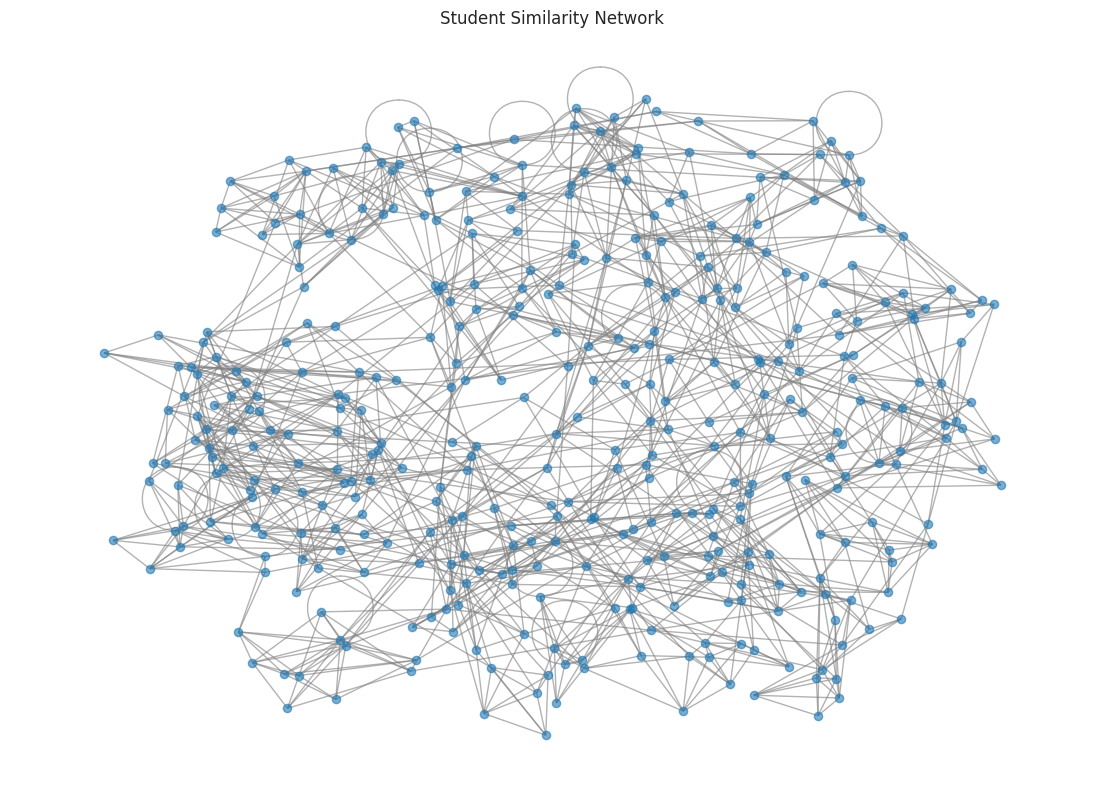

In [34]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.25
)

nx.draw_networkx(
    G,
    pos=pos,
    node_size=35,
    with_labels=False,
    edge_color="gray",
    alpha=0.6
)

plt.title("Student Similarity Network")
plt.axis("off")
plt.show()

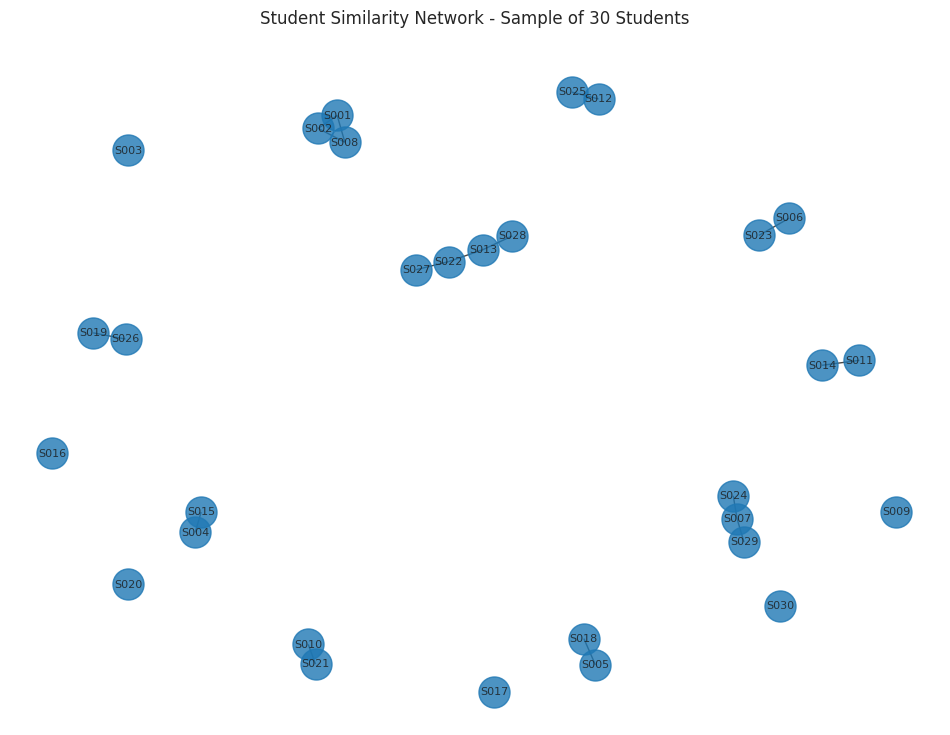

In [35]:
# Visualize a smaller subgraph with student labels

sample_students = list(graph_scaled_df["student_id"][:30])

G_sample = G.subgraph(sample_students)

plt.figure(figsize=(12, 9))

pos_sample = nx.spring_layout(
    G_sample,
    seed=42
)

nx.draw_networkx(
    G_sample,
    pos=pos_sample,
    node_size=500,
    with_labels=True,
    font_size=8,
    alpha=0.8
)

plt.title("Student Similarity Network - Sample of 30 Students")
plt.axis("off")
plt.show()

In [36]:
#STEP 6 — Network Properties + Dijkstra's Algorithm

In [37]:
# Calculate average degree

degrees = dict(G.degree())

average_degree = sum(degrees.values()) / G.number_of_nodes()

print("Average Degree:", round(average_degree, 2))

Average Degree: 6.63


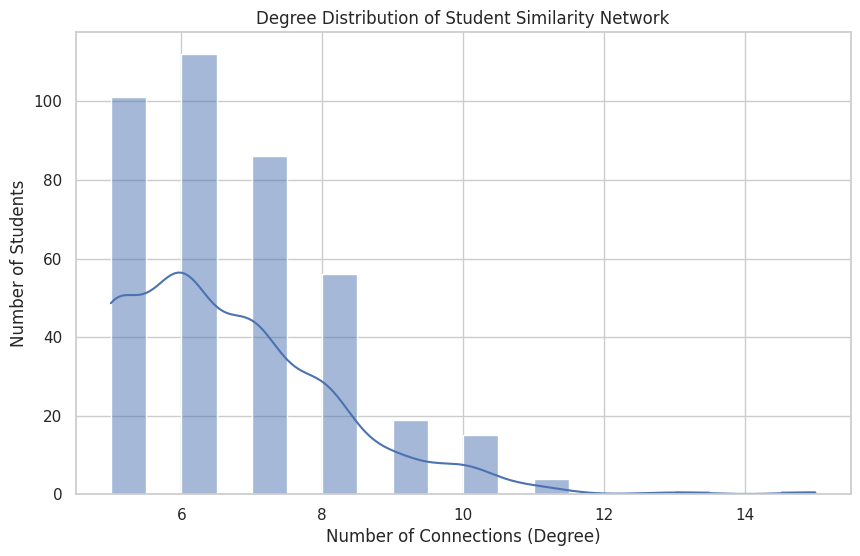

In [38]:
plt.figure(figsize=(10, 6))

degree_values = list(dict(G.degree()).values())

sns.histplot(
    degree_values,
    bins=20,
    kde=True
)

plt.title("Degree Distribution of Student Similarity Network")
plt.xlabel("Number of Connections (Degree)")
plt.ylabel("Number of Students")

plt.show()

In [39]:
average_clustering = nx.average_clustering(G)

print("Average Clustering Coefficient:",
      round(average_clustering, 4))

Average Clustering Coefficient: 0.471


In [40]:
average_path_length = nx.average_shortest_path_length(
    G,
    weight="distance"
)

print(
    "Average Weighted Shortest Path Length:",
    round(average_path_length, 4)
)

Average Weighted Shortest Path Length: 6.4777


In [41]:
print("========== NETWORK SUMMARY ==========")

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Network density:", round(nx.density(G), 4))
print("Average degree:", round(average_degree, 2))
print("Average clustering coefficient:",
      round(average_clustering, 4))
print("Average weighted shortest path:",
      round(average_path_length, 4))
print("Connected components:",
      nx.number_connected_components(G))

========== NETWORK SUMMARY ==========
Number of nodes: 395
Number of edges: 1310
Network density: 0.0168
Average degree: 6.63
Average clustering coefficient: 0.471
Average weighted shortest path: 6.4777
Connected components: 1


In [42]:
source = "S001"
target = "S100"

shortest_path = nx.dijkstra_path(
    G,
    source=source,
    target=target,
    weight="distance"
)

shortest_distance = nx.dijkstra_path_length(
    G,
    source=source,
    target=target,
    weight="distance"
)

print("Source student:", source)
print("Target student:", target)

print("\nDijkstra shortest path:")
print(" → ".join(shortest_path))

print("\nTotal path distance:",
      round(shortest_distance, 4))

Source student: S001
Target student: S100

Dijkstra shortest path:
S001 → S221 → S169 → S091 → S100

Total path distance: 3.6069


In [43]:
print("Edges along the shortest path:")
print("--------------------------------")

total_distance = 0

for i in range(len(shortest_path) - 1):

    student_a = shortest_path[i]
    student_b = shortest_path[i + 1]

    edge = G[student_a][student_b]

    distance = edge["distance"]
    similarity = edge["similarity"]

    total_distance += distance

    print(
        f"{student_a} → {student_b} | "
        f"Distance = {distance:.4f} | "
        f"Similarity = {similarity:.4f}"
    )

print("\nTotal distance:", round(total_distance, 4))

Edges along the shortest path:
--------------------------------
S001 → S221 | Distance = 0.9783 | Similarity = 0.5055
S221 → S169 | Distance = 0.8655 | Similarity = 0.5360
S169 → S091 | Distance = 1.2306 | Similarity = 0.4483
S091 → S100 | Distance = 0.5324 | Similarity = 0.6526

Total distance: 3.6069


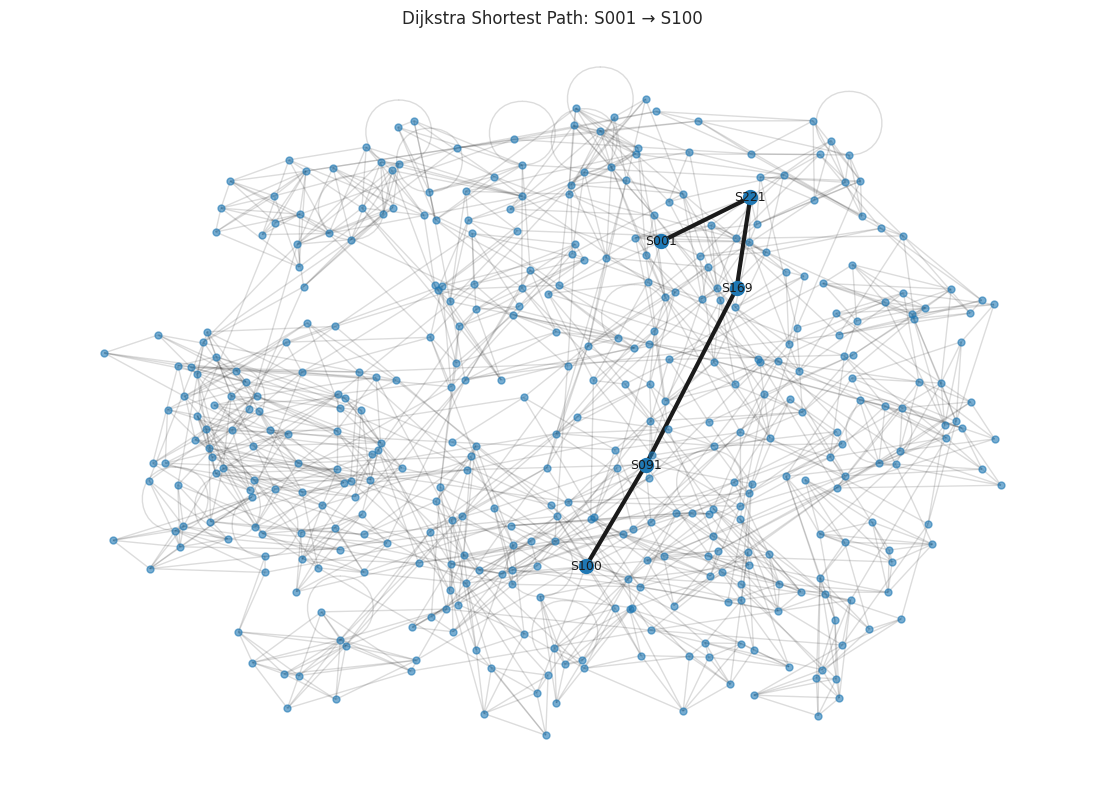

In [44]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.25
)

# Draw all graph edges and nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=25,
    alpha=0.6
)

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.15
)

# Highlight shortest-path nodes
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=shortest_path,
    node_size=100
)

# Highlight shortest-path edges
path_edges = list(zip(
    shortest_path[:-1],
    shortest_path[1:]
))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    width=3
)

# Labels only for path students
path_labels = {
    node: node for node in shortest_path
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=path_labels,
    font_size=9
)

plt.title(
    f"Dijkstra Shortest Path: {source} → {target}"
)

plt.axis("off")
plt.show()

In [45]:
# 1. Degree Centrality

degree_centrality = nx.degree_centrality(G)

print("Top 10 students by Degree Centrality:")
print("--------------------------------------")

top_degree = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for student, score in top_degree:
    print(f"{student}: {score:.4f}")

Top 10 students by Degree Centrality:
--------------------------------------
S059: 0.0381
S085: 0.0330
S020: 0.0279
S035: 0.0279
S110: 0.0279
S118: 0.0279
S016: 0.0254
S024: 0.0254
S049: 0.0254
S063: 0.0254


In [46]:
# 2. Closeness Centrality

closeness_centrality = nx.closeness_centrality(
    G,
    distance="distance"
)

print("Top 10 students by Closeness Centrality:")
print("-----------------------------------------")

top_closeness = sorted(
    closeness_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for student, score in top_closeness:
    print(f"{student}: {score:.4f}")

Top 10 students by Closeness Centrality:
-----------------------------------------
S047: 0.2064
S125: 0.2056
S191: 0.2047
S208: 0.2047
S175: 0.2046
S018: 0.2043
S063: 0.2043
S186: 0.2042
S167: 0.2041
S087: 0.2040


In [47]:
# 3. Betweenness Centrality

betweenness_centrality = nx.betweenness_centrality(
    G,
    weight="distance"
)

print("Top 10 students by Betweenness Centrality:")
print("-------------------------------------------")

top_betweenness = sorted(
    betweenness_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for student, score in top_betweenness:
    print(f"{student}: {score:.4f}")

Top 10 students by Betweenness Centrality:
-------------------------------------------
S091: 0.1245
S182: 0.1143
S336: 0.0969
S208: 0.0930
S125: 0.0896
S117: 0.0816
S227: 0.0815
S100: 0.0808
S191: 0.0684
S317: 0.0662


In [48]:
# 4. Eigenvector Centrality

eigenvector_centrality = nx.eigenvector_centrality(
    G,
    weight="similarity",
    max_iter=1000
)

print("Top 10 students by Eigenvector Centrality:")
print("-------------------------------------------")

top_eigenvector = sorted(
    eigenvector_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for student, score in top_eigenvector:
    print(f"{student}: {score:.4f}")

Top 10 students by Eigenvector Centrality:
-------------------------------------------
S059: 0.4816
S085: 0.4073
S031: 0.2788
S014: 0.2734
S065: 0.2658
S148: 0.2392
S034: 0.2379
S069: 0.2147
S146: 0.2079
S127: 0.1876


In [49]:
# 5. PageRank

pagerank = nx.pagerank(
    G,
    weight="similarity"
)

print("Top 10 students by PageRank:")
print("-----------------------------")

top_pagerank = sorted(
    pagerank.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for student, score in top_pagerank:
    print(f"{student}: {score:.6f}")

Top 10 students by PageRank:
-----------------------------
S059: 0.005042
S085: 0.004607
S110: 0.004128
S020: 0.004109
S118: 0.004026
S035: 0.003982
S386: 0.003885
S228: 0.003862
S288: 0.003840
S063: 0.003762


In [50]:
# Combine all centrality measures into one DataFrame

centrality_df = pd.DataFrame({
    "student_id": list(G.nodes()),
    "degree_centrality": [
        degree_centrality[node] for node in G.nodes()
    ],
    "closeness_centrality": [
        closeness_centrality[node] for node in G.nodes()
    ],
    "betweenness_centrality": [
        betweenness_centrality[node] for node in G.nodes()
    ],
    "eigenvector_centrality": [
        eigenvector_centrality[node] for node in G.nodes()
    ],
    "pagerank": [
        pagerank[node] for node in G.nodes()
    ]
})

print("Centrality DataFrame shape:")
print(centrality_df.shape)

display(centrality_df.head())

Centrality DataFrame shape:
(395, 6)


,student_id,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,pagerank
0,S001,0.020305,0.191712,0.016923,0.000604,0.002712
1,S002,0.017766,0.193822,0.000386,0.001214,0.002765
2,S003,0.015228,0.126861,0.004026,0.000559,0.002386
3,S004,0.015228,0.135014,0.002450,0.000014,0.002459
4,S005,0.012690,0.187701,0.000000,0.004245,0.001940


In [51]:
# Add final grade for analysis

centrality_df = centrality_df.merge(
    target_df,
    on="student_id"
)

print(centrality_df.head())

  student_id  degree_centrality  closeness_centrality  betweenness_centrality  \
0       S001           0.020305              0.191712                0.016923   
1       S002           0.017766              0.193822                0.000386   
2       S003           0.015228              0.126861                0.004026   
3       S004           0.015228              0.135014                0.002450   
4       S005           0.012690              0.187701                0.000000   

   eigenvector_centrality  pagerank  G3  
0                0.000604  0.002712   6  
1                0.001214  0.002765   6  
2                0.000559  0.002386  10  
3                0.000014  0.002459  15  
4                0.004245  0.001940  10  


In [52]:
centrality_columns = [
    "degree_centrality",
    "closeness_centrality",
    "betweenness_centrality",
    "eigenvector_centrality",
    "pagerank"
]

centrality_g3_corr = centrality_df[
    centrality_columns + ["G3"]
].corr()["G3"].sort_values(
    ascending=False
)

print("Correlation between graph measures and G3:")
print("--------------------------------------------")
print(centrality_g3_corr)

Correlation between graph measures and G3:
--------------------------------------------
G3                        1.000000
pagerank                  0.048393
degree_centrality         0.021040
eigenvector_centrality   -0.007834
betweenness_centrality   -0.051594
closeness_centrality     -0.132348
Name: G3, dtype: float64


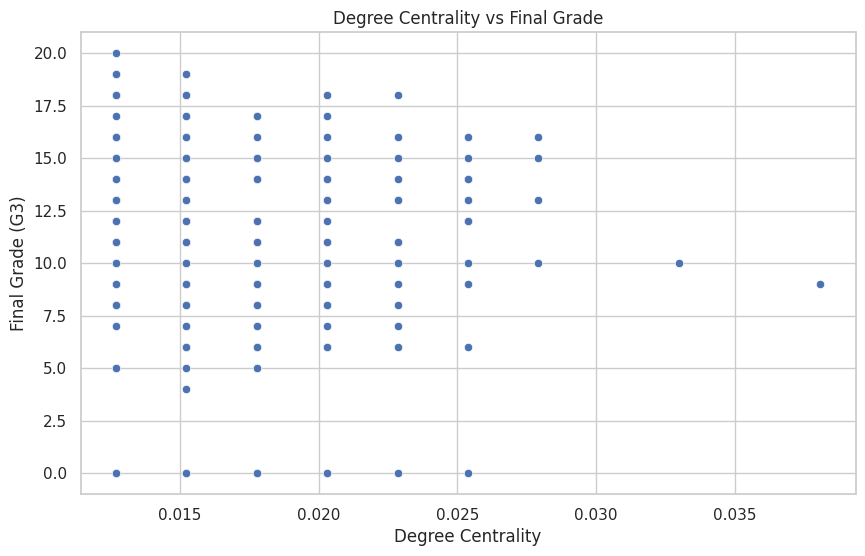

In [53]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=centrality_df,
    x="degree_centrality",
    y="G3"
)

plt.title("Degree Centrality vs Final Grade")
plt.xlabel("Degree Centrality")
plt.ylabel("Final Grade (G3)")

plt.show()

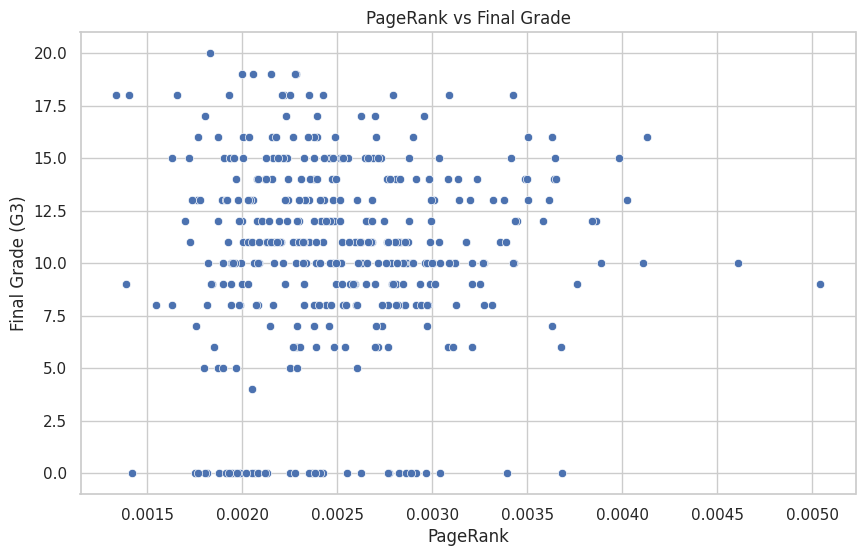

In [54]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=centrality_df,
    x="pagerank",
    y="G3"
)

plt.title("PageRank vs Final Grade")
plt.xlabel("PageRank")
plt.ylabel("Final Grade (G3)")

plt.show()

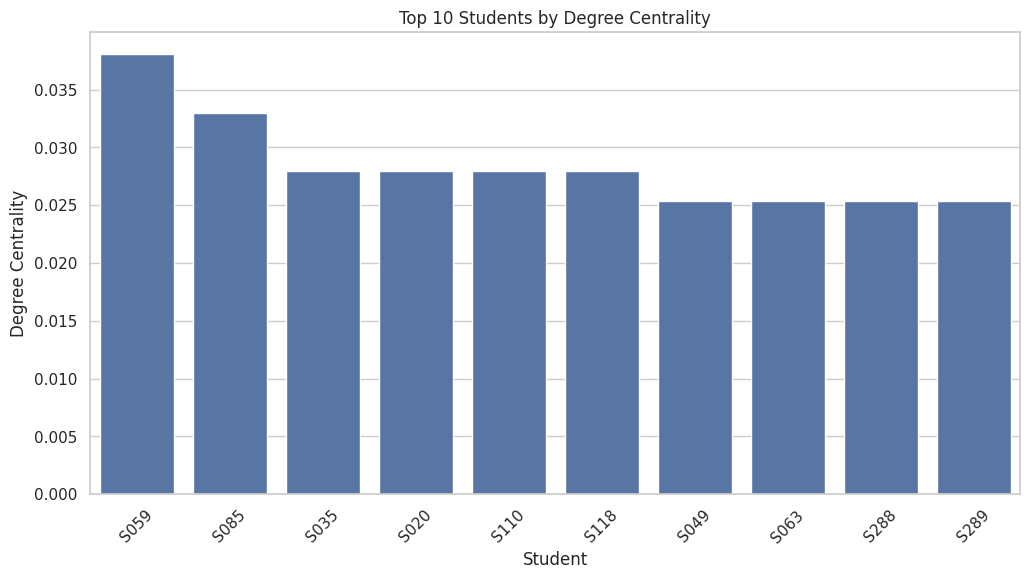

In [55]:
top_10_degree = centrality_df.sort_values(
    "degree_centrality",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_degree,
    x="student_id",
    y="degree_centrality"
)

plt.title("Top 10 Students by Degree Centrality")
plt.xlabel("Student")
plt.ylabel("Degree Centrality")

plt.xticks(rotation=45)

plt.show()

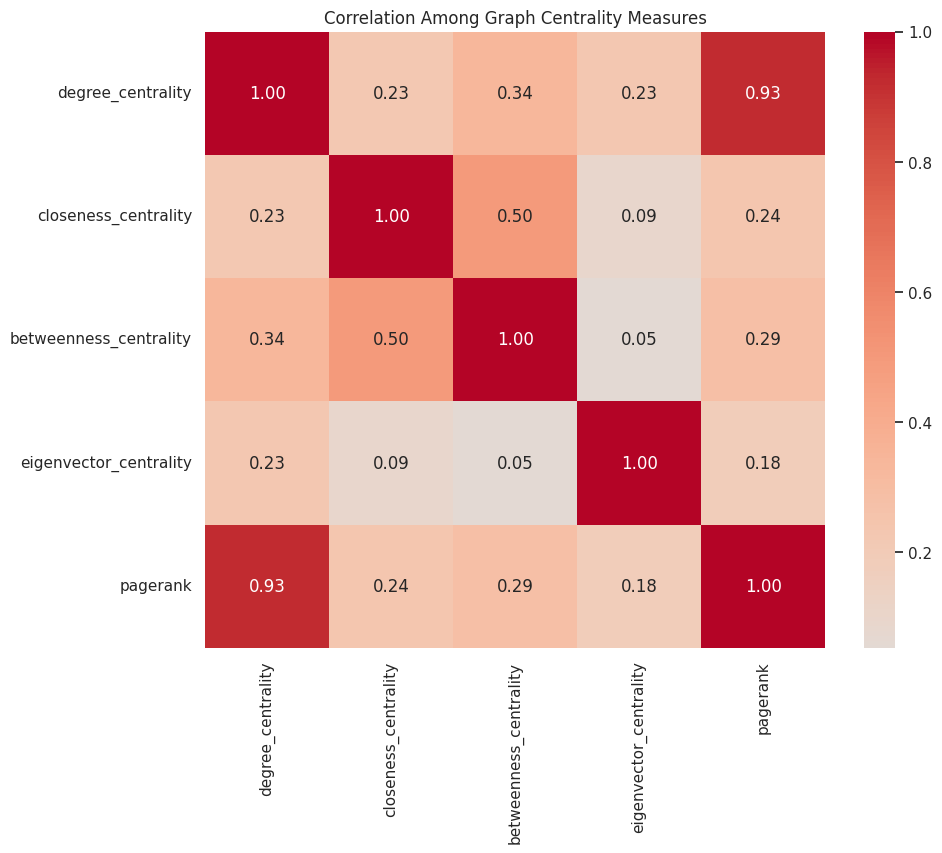

In [56]:
centrality_corr = centrality_df[
    centrality_columns
].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    centrality_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Among Graph Centrality Measures")

plt.show()

In [57]:
# STEP 8.1 - Community detection using greedy modularity

communities = nx.community.greedy_modularity_communities(
    G,
    weight="similarity"
)

print("Number of communities:", len(communities))

print("\nCommunity sizes:")
for i, community in enumerate(communities, start=1):
    print(f"Community {i}: {len(community)} students")

Number of communities: 13

Community sizes:
Community 1: 81 students
Community 2: 64 students
Community 3: 40 students
Community 4: 36 students
Community 5: 35 students
Community 6: 33 students
Community 7: 24 students
Community 8: 16 students
Community 9: 16 students
Community 10: 16 students
Community 11: 14 students
Community 12: 11 students
Community 13: 9 students


In [58]:
# Assign each student to a community

community_mapping = {}

for community_id, community in enumerate(communities, start=1):
    for student in community:
        community_mapping[student] = community_id

centrality_df["community"] = centrality_df["student_id"].map(
    community_mapping
)

print("Community assignment:")
display(
    centrality_df[
        ["student_id", "community", "G3"]
    ].head(10)
)

Community assignment:


,student_id,community,G3
0,S001,13,6
1,S002,13,6
2,S003,1,10
3,S004,2,15
4,S005,3,10
5,S006,7,15
6,S007,7,11
7,S008,13,6
8,S009,12,19
9,S010,12,15


In [59]:
print(
    "Students assigned to communities:",
    centrality_df["community"].notna().sum()
)

print(
    "Students without community:",
    centrality_df["community"].isna().sum()
)

Students assigned to communities: 395
Students without community: 0


In [60]:
# Analyze final grade by community

community_performance = (
    centrality_df
    .groupby("community")["G3"]
    .agg(
        students="count",
        average_G3="mean",
        median_G3="median",
        minimum_G3="min",
        maximum_G3="max"
    )
    .round(2)
)

display(community_performance)

,students,average_G3,median_G3,minimum_G3,maximum_G3
community,,,,,
1,81,7.09,8.0,0,15
2,64,12.36,13.0,0,20
3,40,9.62,10.0,0,14
4,36,8.42,10.0,0,13
5,35,14.37,14.0,10,19
6,33,11.64,11.0,0,18
7,24,14.00,14.0,11,17
8,16,9.31,9.5,6,12
9,16,10.12,11.0,0,16


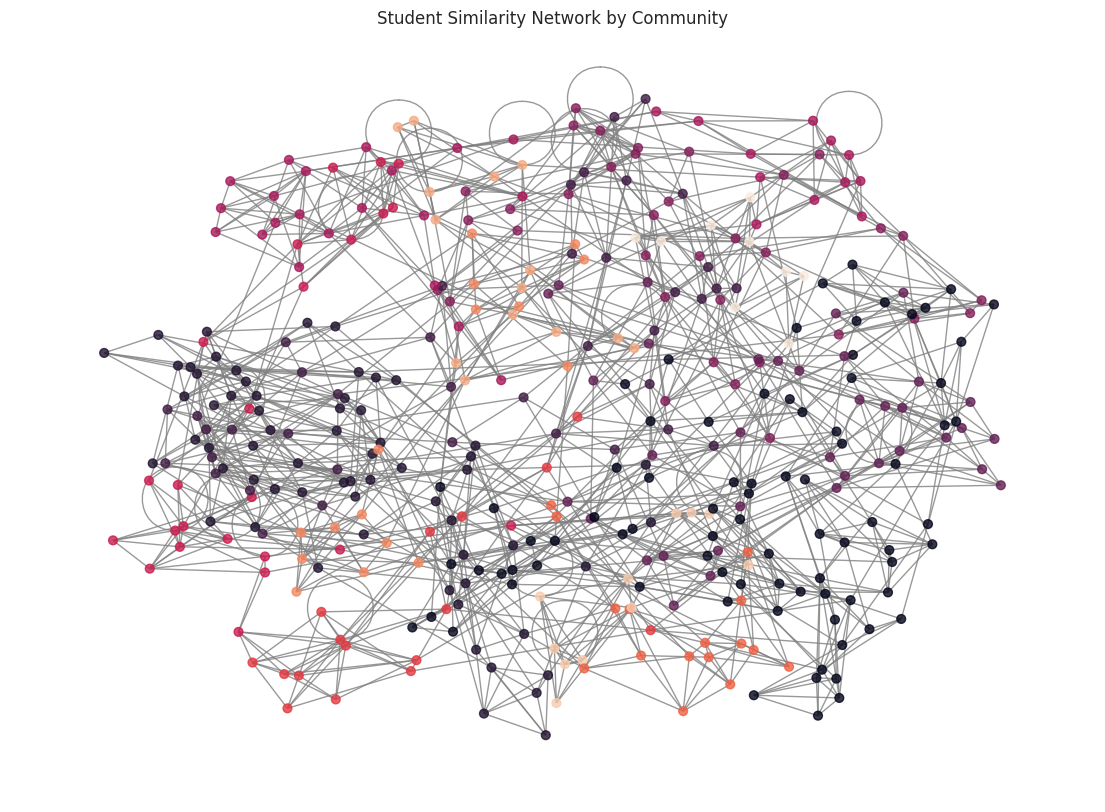

In [61]:
# Create a color index for each node based on community

node_colors = [
    community_mapping[node]
    for node in G.nodes()
]

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.25
)

nx.draw_networkx(
    G,
    pos=pos,
    node_color=node_colors,
    node_size=40,
    with_labels=False,
    alpha=0.8,
    edge_color="gray"
)

plt.title("Student Similarity Network by Community")
plt.axis("off")
plt.show()

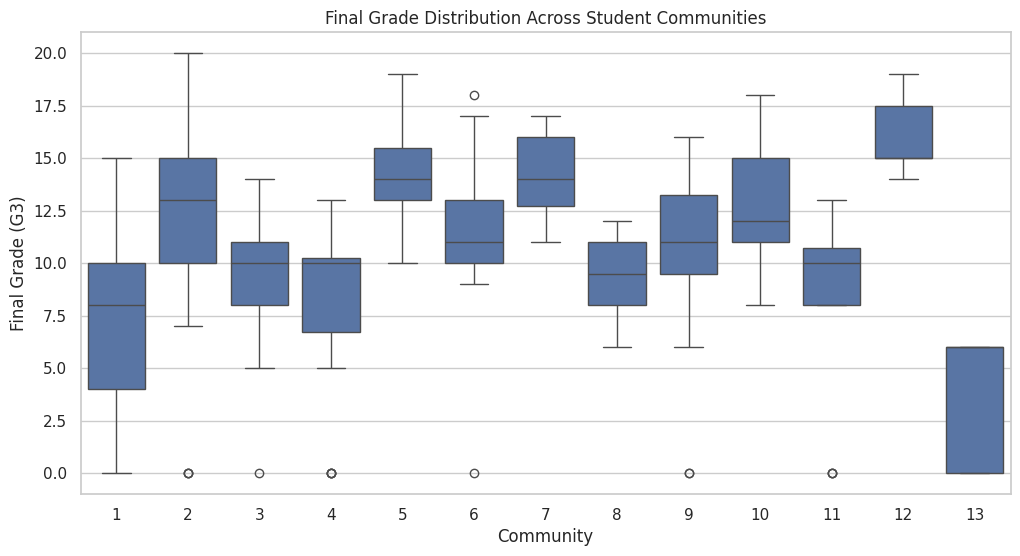

In [62]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=centrality_df,
    x="community",
    y="G3"
)

plt.title("Final Grade Distribution Across Student Communities")
plt.xlabel("Community")
plt.ylabel("Final Grade (G3)")

plt.show()

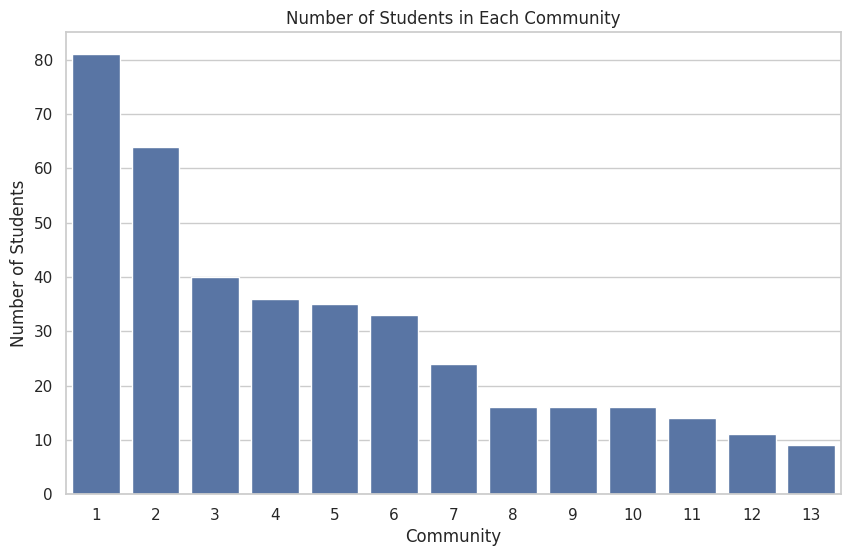

In [63]:
community_sizes = (
    centrality_df["community"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=community_sizes.index.astype(str),
    y=community_sizes.values
)

plt.title("Number of Students in Each Community")
plt.xlabel("Community")
plt.ylabel("Number of Students")

plt.show()

In [64]:
# Add selected original variables for community analysis

community_analysis_df = df[
    [
        "age",
        "studytime",
        "failures",
        "absences",
        "G1",
        "G2",
        "G3"
    ]
].copy()

community_analysis_df["student_id"] = [
    f"S{i+1:03d}" for i in range(len(df))
]

community_analysis_df = community_analysis_df.merge(
    centrality_df[["student_id", "community"]],
    on="student_id"
)

community_summary = (
    community_analysis_df
    .groupby("community")
    [
        [
            "age",
            "studytime",
            "failures",
            "absences",
            "G1",
            "G2",
            "G3"
        ]
    ]
    .mean()
    .round(2)
)

display(community_summary)

,age,studytime,failures,absences,G1,G2,G3
community,,,,,,,
1,17.51,1.78,1.57,9.93,8.69,8.19,7.09
2,16.89,3.17,0.00,3.52,12.62,12.36,12.36
3,16.23,1.90,0.00,10.52,9.60,9.75,9.62
4,16.72,1.03,0.00,5.19,9.00,8.42,8.42
5,15.71,1.00,0.03,3.57,13.77,14.34,14.37
6,17.15,1.97,0.00,2.36,11.82,11.58,11.64
7,15.83,2.00,0.04,1.67,13.50,13.88,14.00
8,15.00,2.00,0.06,2.75,8.69,9.12,9.31
9,15.38,4.00,0.06,4.50,10.56,11.25,10.12


In [65]:
# STEP 8.11 - Hierarchical community detection
# Girvan-Newman algorithm

from networkx.algorithms.community import girvan_newman

gn_generator = girvan_newman(G)

print("Hierarchical community levels:")
print("--------------------------------")

for level in range(4):
    communities_level = next(gn_generator)

    print(
        f"Level {level + 1}: "
        f"{len(communities_level)} communities"
    )

Hierarchical community levels:
--------------------------------
Level 1: 2 communities
Level 2: 3 communities
Level 3: 4 communities
Level 4: 5 communities


In [66]:
# Get a 4-community partition from Girvan-Newman

gn_generator = girvan_newman(G)

gn_level_4 = None

for _ in range(3):
    gn_level_4 = next(gn_generator)

print("Number of communities:", len(gn_level_4))

for i, community in enumerate(gn_level_4, start=1):
    print(
        f"Community {i}: {len(community)} students"
    )

Number of communities: 4
Community 1: 268 students
Community 2: 80 students
Community 3: 12 students
Community 4: 35 students


In [67]:
# STEP 9.1 - Create the machine learning dataset

ml_df = df[
    [
        "age",
        "studytime",
        "failures",
        "absences",
        "G1",
        "G2",
        "G3"
    ]
].copy()

# Add student IDs
ml_df["student_id"] = [
    f"S{i+1:03d}" for i in range(len(ml_df))
]

# Add graph-derived features
graph_features_df = centrality_df[
    [
        "student_id",
        "degree_centrality",
        "closeness_centrality",
        "betweenness_centrality",
        "eigenvector_centrality",
        "pagerank",
        "community"
    ]
].copy()

# Merge
ml_df = ml_df.merge(
    graph_features_df,
    on="student_id"
)

print("ML dataset shape:", ml_df.shape)

display(ml_df.head())

ML dataset shape: (395, 14)


,age,studytime,failures,absences,G1,G2,G3,student_id,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,pagerank,community
0,18,2,0,6,5,6,6,S001,0.020305,0.191712,0.016923,0.000604,0.002712,13
1,17,2,0,4,5,5,6,S002,0.017766,0.193822,0.000386,0.001214,0.002765,13
2,15,2,3,10,7,8,10,S003,0.015228,0.126861,0.004026,0.000559,0.002386,1
3,15,3,0,2,15,14,15,S004,0.015228,0.135014,0.002450,0.000014,0.002459,2
4,16,2,0,4,6,10,10,S005,0.012690,0.187701,0.000000,0.004245,0.001940,3


In [68]:
# Separate target and features

X = ml_df.drop(
    columns=["G3", "student_id"]
)

y = ml_df["G3"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (395, 12)
Target shape: (395,)


In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 316
Testing samples: 79


In [70]:
from sklearn.ensemble import RandomForestRegressor

# Traditional Random Forest
rf_traditional = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    n_jobs=-1
)

rf_traditional.fit(
    X_train[
        [
            "age",
            "studytime",
            "failures",
            "absences",
            "G1",
            "G2"
        ]
    ],
    y_train
)

print("Traditional Random Forest trained successfully!")

Traditional Random Forest trained successfully!


In [71]:
traditional_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

y_pred_traditional = rf_traditional.predict(
    X_test[traditional_features]
)

print("First 10 predictions:")

for actual, predicted in zip(
    y_test.iloc[:10],
    y_pred_traditional[:10]
):
    print(
        f"Actual = {actual:.0f}, "
        f"Predicted = {predicted:.2f}"
    )

First 10 predictions:
Actual = 10, Predicted = 8.56
Actual = 12, Predicted = 11.64
Actual = 5, Predicted = 7.01
Actual = 10, Predicted = 9.62
Actual = 9, Predicted = 9.12
Actual = 13, Predicted = 13.29
Actual = 18, Predicted = 18.93
Actual = 6, Predicted = 6.71
Actual = 0, Predicted = 2.50
Actual = 14, Predicted = 12.93


In [72]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

rmse_traditional = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_traditional
    )
)

mae_traditional = mean_absolute_error(
    y_test,
    y_pred_traditional
)

r2_traditional = r2_score(
    y_test,
    y_pred_traditional
)

print("===== TRADITIONAL RANDOM FOREST =====")

print("RMSE:", round(rmse_traditional, 4))
print("MAE :", round(mae_traditional, 4))
print("R²  :", round(r2_traditional, 4))

===== TRADITIONAL RANDOM FOREST =====
RMSE: 1.7065
MAE : 1.037
R²  : 0.858


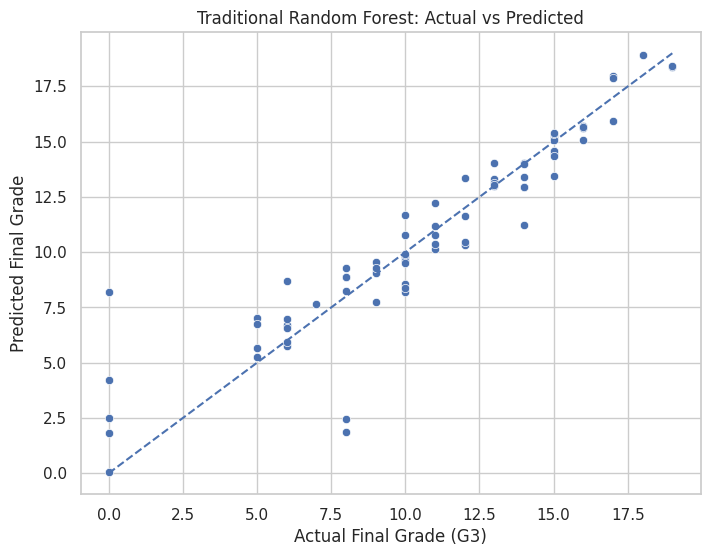

In [73]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_traditional
)

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")
plt.title("Traditional Random Forest: Actual vs Predicted")

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_traditional.min())
max_value = max(y_test.max(), y_pred_traditional.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [74]:
graph_ml_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "degree_centrality",
    "closeness_centrality",
    "betweenness_centrality",
    "eigenvector_centrality",
    "pagerank",
    "community"
]

In [75]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

graph_features_ml = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "degree_centrality",
    "closeness_centrality",
    "betweenness_centrality",
    "eigenvector_centrality",
    "pagerank",
    "community"
]

numeric_graph_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "degree_centrality",
    "closeness_centrality",
    "betweenness_centrality",
    "eigenvector_centrality",
    "pagerank"
]

categorical_graph_features = [
    "community"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_graph_features
        )
    ],
    remainder="passthrough"
)

rf_graph = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

graph_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_graph)
    ]
)

graph_pipeline.fit(
    X_train[graph_features_ml],
    y_train
)

print("Graph-enhanced Random Forest trained successfully!")

Graph-enhanced Random Forest trained successfully!


In [76]:
y_pred_graph = graph_pipeline.predict(
    X_test[graph_features_ml]
)

print("First 10 graph-enhanced predictions:")

for actual, predicted in zip(
    y_test.iloc[:10],
    y_pred_graph[:10]
):
    print(
        f"Actual = {actual:.0f}, "
        f"Predicted = {predicted:.2f}"
    )

First 10 graph-enhanced predictions:
Actual = 10, Predicted = 8.53
Actual = 12, Predicted = 11.79
Actual = 5, Predicted = 5.91
Actual = 10, Predicted = 9.33
Actual = 9, Predicted = 8.24
Actual = 13, Predicted = 12.93
Actual = 18, Predicted = 19.00
Actual = 6, Predicted = 6.76
Actual = 0, Predicted = 3.08
Actual = 14, Predicted = 12.95


In [77]:
rmse_graph = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_graph
    )
)

mae_graph = mean_absolute_error(
    y_test,
    y_pred_graph
)

r2_graph = r2_score(
    y_test,
    y_pred_graph
)

print("===== GRAPH-ENHANCED RANDOM FOREST =====")

print("RMSE:", round(rmse_graph, 4))
print("MAE :", round(mae_graph, 4))
print("R²  :", round(r2_graph, 4))

===== GRAPH-ENHANCED RANDOM FOREST =====
RMSE: 1.6539
MAE : 1.028
R²  : 0.8666


In [78]:
comparison_df = pd.DataFrame({
    "Model": [
        "Traditional Random Forest",
        "Graph-Enhanced Random Forest"
    ],
    "RMSE": [
        rmse_traditional,
        rmse_graph
    ],
    "MAE": [
        mae_traditional,
        mae_graph
    ],
    "R2": [
        r2_traditional,
        r2_graph
    ]
})

comparison_df = comparison_df.round(4)

display(comparison_df)

,Model,RMSE,MAE,R2
0,Traditional Random Forest,1.7065,1.037,0.8580
1,Graph-Enhanced Random Forest,1.6539,1.028,0.8666


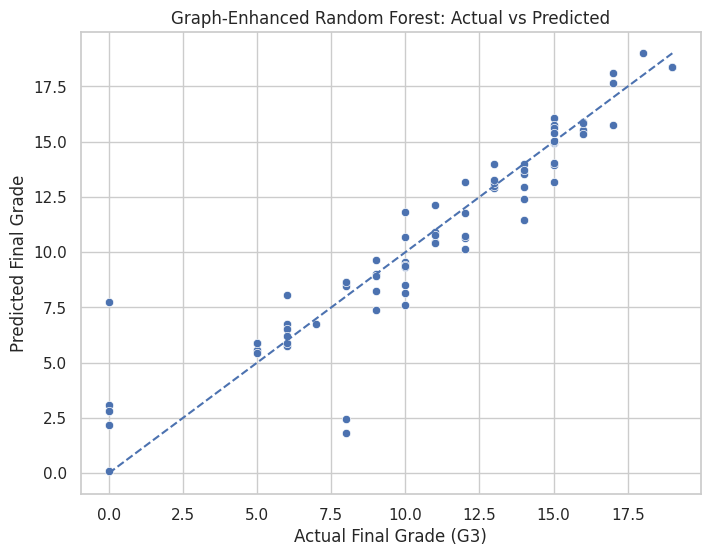

In [79]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_graph
)

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")
plt.title("Graph-Enhanced Random Forest: Actual vs Predicted")

min_value = min(y_test.min(), y_pred_graph.min())
max_value = max(y_test.max(), y_pred_graph.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

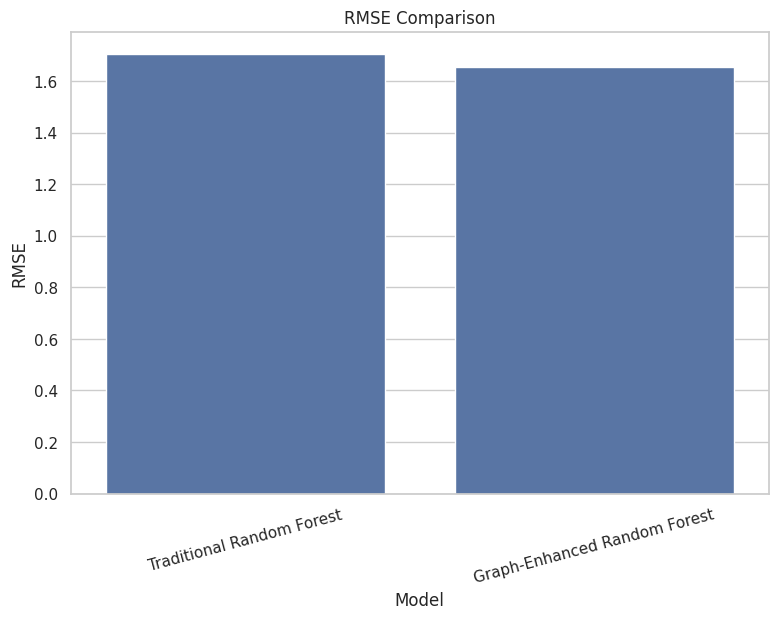

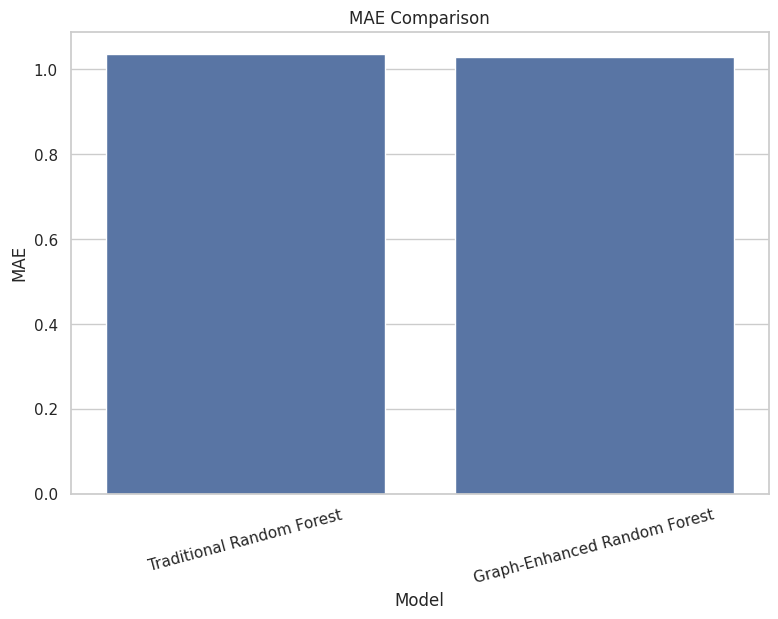

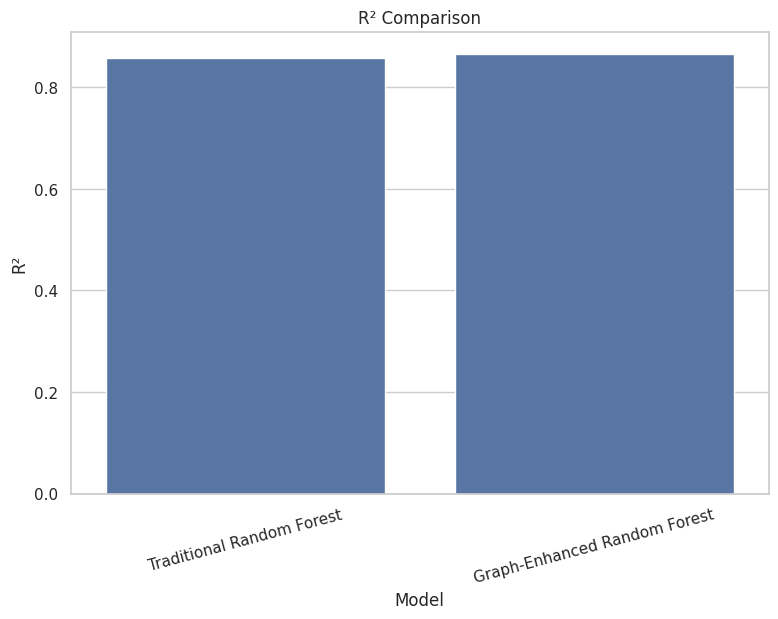

In [80]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.xticks(rotation=15)

plt.show()


plt.figure(figsize=(9, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(rotation=15)

plt.show()


plt.figure(figsize=(9, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="R2"
)

plt.title("R² Comparison")
plt.xlabel("Model")
plt.ylabel("R²")

plt.xticks(rotation=15)

plt.show()

,feature,importance
18,remainder__G2,0.787861
16,remainder__absences,0.114419
13,remainder__age,0.020290
21,remainder__betweenness_centrality,0.015429
23,remainder__pagerank,0.013818
22,remainder__eigenvector_centrality,0.013316
20,remainder__closeness_centrality,0.010175
17,remainder__G1,0.008677
19,remainder__degree_centrality,0.003719
14,remainder__studytime,0.003159


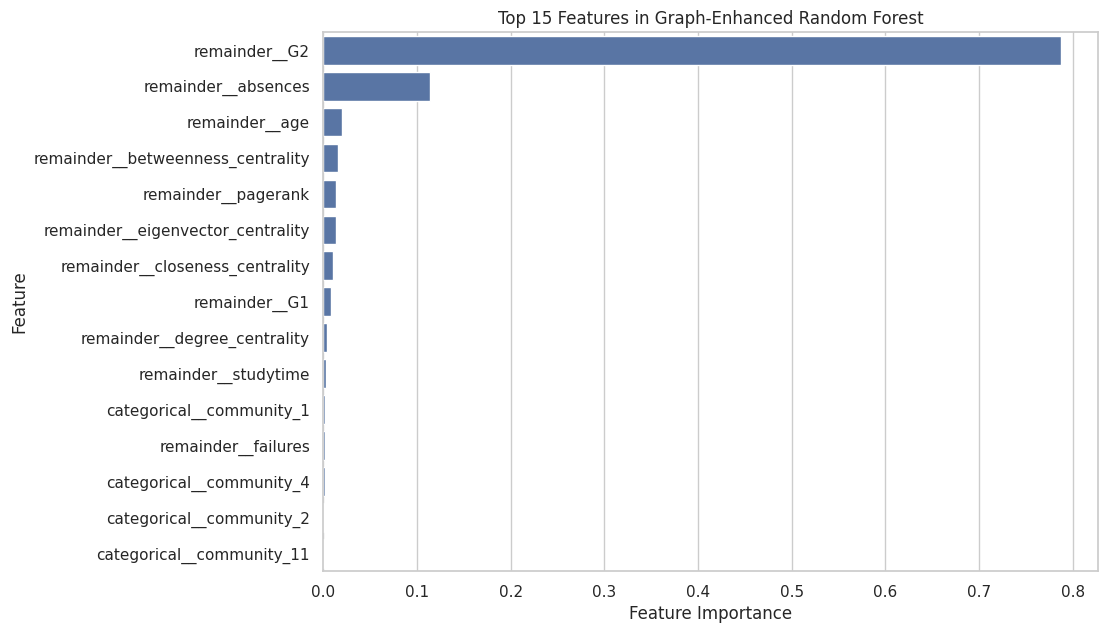

In [81]:
# Get transformed feature names

feature_names = (
    graph_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    graph_pipeline
    .named_steps["model"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    "importance",
    ascending=False
)

display(
    feature_importance_df.head(15)
)




top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title(
    "Top 15 Features in Graph-Enhanced Random Forest"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

In [82]:
# Calculate performance differences

rmse_change = rmse_traditional - rmse_graph
mae_change = mae_traditional - mae_graph
r2_change = r2_graph - r2_traditional

print("========== GRAPH FEATURE IMPACT ==========")

print(
    f"RMSE change: {rmse_change:.4f}"
)

print(
    f"MAE change: {mae_change:.4f}"
)

print(
    f"R² change: {r2_change:.4f}"
)

========== GRAPH FEATURE IMPACT ==========
RMSE change: 0.0525
MAE change: 0.0090
R² change: 0.0086


In [83]:
rmse_improvement = (
    (rmse_traditional - rmse_graph)
    / rmse_traditional
) * 100

mae_improvement = (
    (mae_traditional - mae_graph)
    / mae_traditional
) * 100

r2_improvement = (
    (r2_graph - r2_traditional)
    / abs(r2_traditional)
) * 100

print("========== PERCENTAGE CHANGE ==========")

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

print(
    f"MAE improvement: {mae_improvement:.2f}%"
)

print(
    f"R² improvement: {r2_improvement:.2f}%"
)

========== PERCENTAGE CHANGE ==========
RMSE improvement: 3.08%
MAE improvement: 0.87%
R² improvement: 1.00%


In [84]:
graph_feature_columns = [
    "degree_centrality",
    "closeness_centrality",
    "betweenness_centrality",
    "eigenvector_centrality",
    "pagerank"
]

graph_feature_summary = centrality_df[
    graph_feature_columns
].describe().T

display(graph_feature_summary)

,count,mean,std,min,25%,50%,75%,max
degree_centrality,395.0,0.016835,0.003823,1.269036e-02,0.012690,0.015228,0.017766,0.038071
closeness_centrality,395.0,0.158599,0.025464,8.383862e-02,0.139731,0.155780,0.180602,0.206387
betweenness_centrality,395.0,0.013945,0.017649,0.000000e+00,0.002105,0.008442,0.019060,0.124455
eigenvector_centrality,395.0,0.011007,0.049159,2.513287e-07,0.000006,0.000050,0.000586,0.481632
pagerank,395.0,0.002532,0.000543,1.333954e-03,0.002131,0.002464,0.002844,0.005042


In [85]:
graph_g3_correlation = (
    centrality_df[
        graph_feature_columns + ["G3"]
    ]
    .corr()["G3"]
    .drop("G3")
    .sort_values(
        ascending=False
    )
)

print("========== GRAPH FEATURE vs G3 ==========")

display(graph_g3_correlation)

========== GRAPH FEATURE vs G3 ==========


,G3
pagerank,0.048393
degree_centrality,0.021040
eigenvector_centrality,-0.007834
betweenness_centrality,-0.051594
closeness_centrality,-0.132348


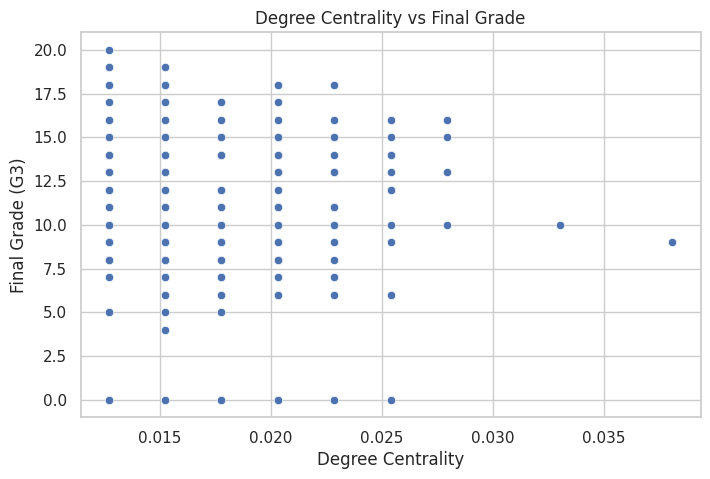

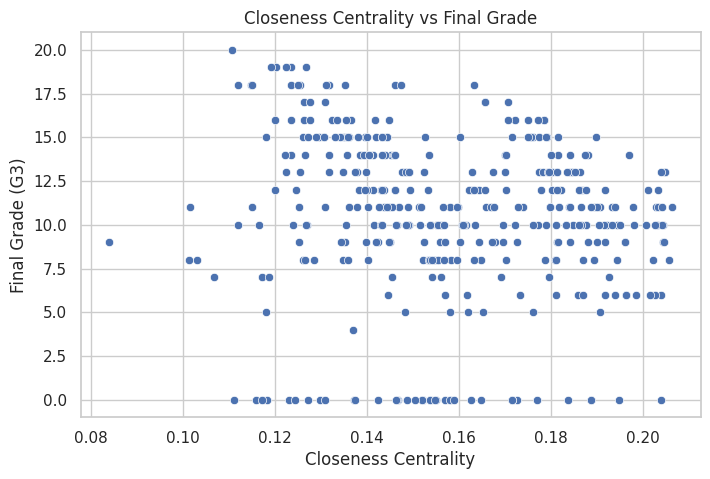

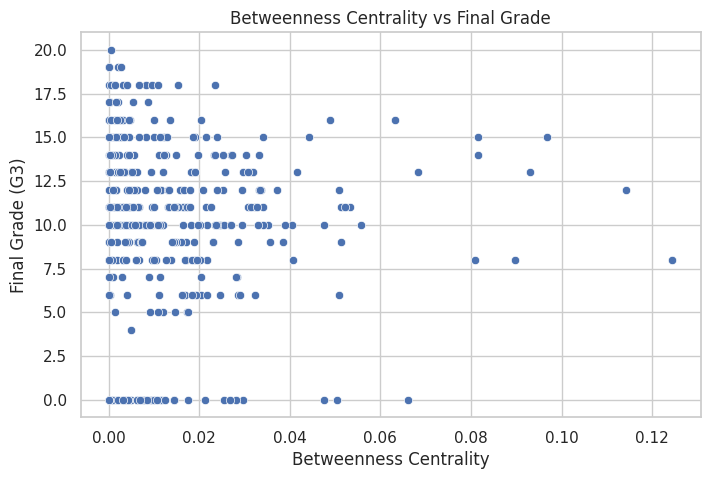

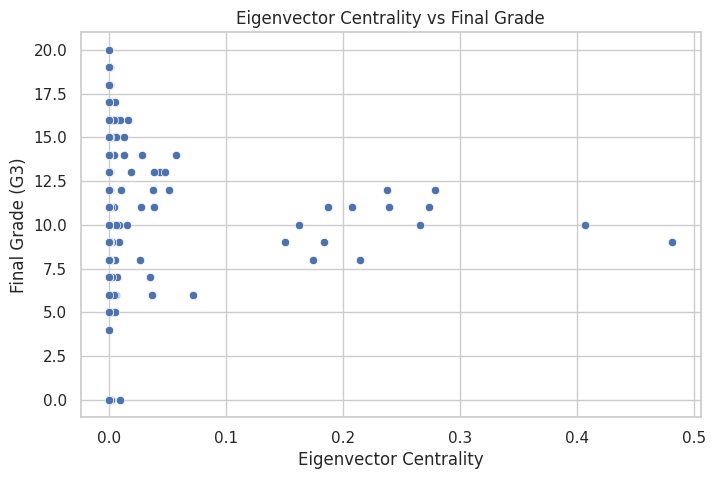

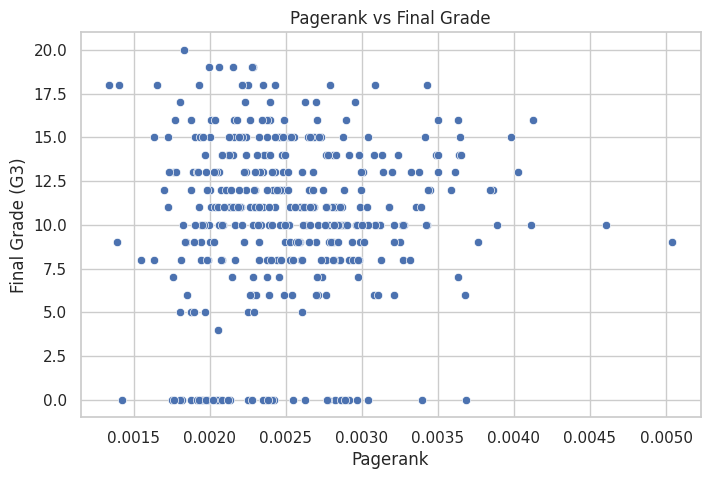

In [86]:
for feature in graph_feature_columns:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=centrality_df,
        x=feature,
        y="G3"
    )

    plt.title(
        f"{feature.replace('_', ' ').title()} vs Final Grade"
    )

    plt.xlabel(
        feature.replace("_", " ").title()
    )

    plt.ylabel("Final Grade (G3)")

    plt.show()

In [87]:
clean_feature_importance = feature_importance_df.copy()

clean_feature_importance["feature"] = (
    clean_feature_importance["feature"]
    .str.replace("remainder__", "", regex=False)
    .str.replace("categorical__community_", "community_", regex=False)
)

display(
    clean_feature_importance.head(15)
)

,feature,importance
18,G2,0.787861
16,absences,0.114419
13,age,0.020290
21,betweenness_centrality,0.015429
23,pagerank,0.013818
22,eigenvector_centrality,0.013316
20,closeness_centrality,0.010175
17,G1,0.008677
19,degree_centrality,0.003719
14,studytime,0.003159


,feature,importance
21,betweenness_centrality,0.015429
23,pagerank,0.013818
22,eigenvector_centrality,0.013316
20,closeness_centrality,0.010175
19,degree_centrality,0.003719


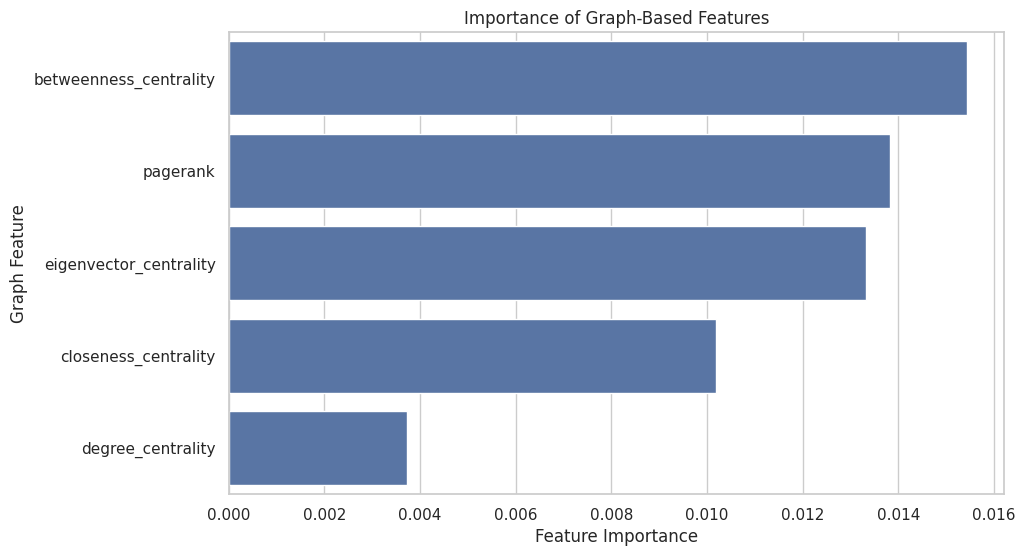

In [88]:
graph_importance = clean_feature_importance[
    clean_feature_importance["feature"].isin(
        [
            "degree_centrality",
            "closeness_centrality",
            "betweenness_centrality",
            "eigenvector_centrality",
            "pagerank"
        ]
    )
].copy()

display(graph_importance)


plt.figure(figsize=(10, 6))

sns.barplot(
    data=graph_importance,
    x="importance",
    y="feature"
)

plt.title(
    "Importance of Graph-Based Features"
)

plt.xlabel("Feature Importance")
plt.ylabel("Graph Feature")

plt.show()

In [89]:
prediction_results = pd.DataFrame({
    "Actual_G3": y_test.values,
    "Predicted_G3": y_pred_graph
})

prediction_results["Error"] = (
    prediction_results["Actual_G3"]
    - prediction_results["Predicted_G3"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Error"].abs()
)

display(
    prediction_results.head(15)
)

,Actual_G3,Predicted_G3,Error,Absolute_Error
0,10,8.526667,1.473333,1.473333
1,12,11.793333,0.206667,0.206667
2,5,5.910000,-0.910000,0.910000
3,10,9.333333,0.666667,0.666667
4,9,8.240000,0.760000,0.760000
5,13,12.926667,0.073333,0.073333
6,18,19.003333,-1.003333,1.003333
7,6,6.760000,-0.760000,0.760000
8,0,3.080000,-3.080000,3.080000
9,14,12.953333,1.046667,1.046667


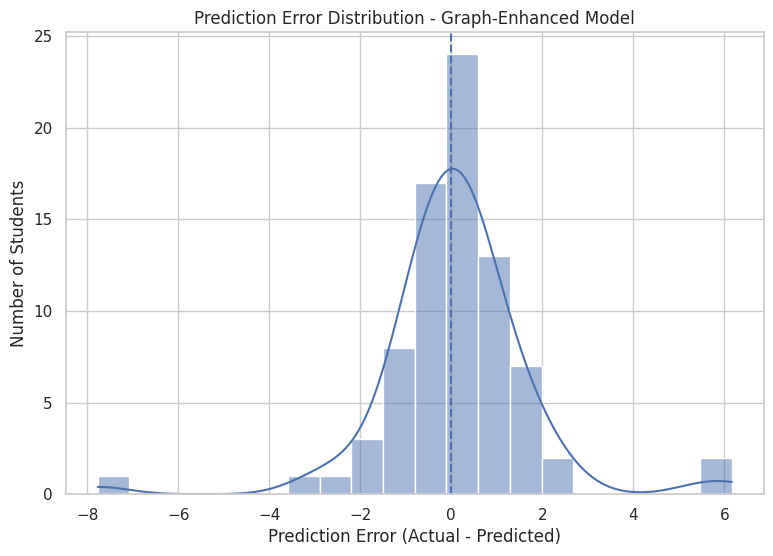

In [90]:
plt.figure(figsize=(9, 6))

sns.histplot(
    prediction_results["Error"],
    bins=20,
    kde=True
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Prediction Error Distribution - Graph-Enhanced Model"
)

plt.xlabel(
    "Prediction Error (Actual - Predicted)"
)

plt.ylabel("Number of Students")

plt.show()

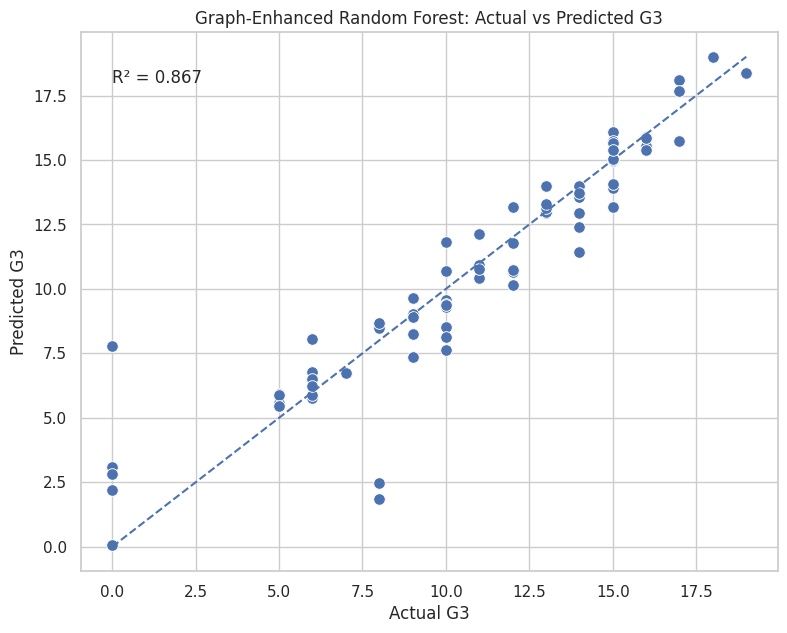

In [91]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred_graph,
    s=70
)

min_value = min(
    y_test.min(),
    y_pred_graph.min()
)

max_value = max(
    y_test.max(),
    y_pred_graph.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.text(
    min_value,
    max_value - 1,
    f"R² = {r2_graph:.3f}",
    fontsize=12
)

plt.title(
    "Graph-Enhanced Random Forest: Actual vs Predicted G3"
)

plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")

plt.show()

In [92]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

traditional_cv_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

traditional_cv = cross_validate(
    rf_traditional,
    ml_df[traditional_cv_features],
    ml_df["G3"],
    cv=cv,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    n_jobs=-1
)

traditional_cv_rmse = (
    -traditional_cv["test_RMSE"]
).mean()

traditional_cv_mae = (
    -traditional_cv["test_MAE"]
).mean()

traditional_cv_r2 = (
    traditional_cv["test_R2"]
).mean()

print("===== 5-FOLD CV: TRADITIONAL RF =====")

print("Mean RMSE:", round(traditional_cv_rmse, 4))
print("Mean MAE :", round(traditional_cv_mae, 4))
print("Mean R²  :", round(traditional_cv_r2, 4))

===== 5-FOLD CV: TRADITIONAL RF =====
Mean RMSE: 1.566
Mean MAE : 0.9651
Mean R²  : 0.8786


In [93]:
graph_cv = cross_validate(
    graph_pipeline,
    ml_df[graph_features_ml],
    ml_df["G3"],
    cv=cv,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    n_jobs=-1
)

graph_cv_rmse = (
    -graph_cv["test_RMSE"]
).mean()

graph_cv_mae = (
    -graph_cv["test_MAE"]
).mean()

graph_cv_r2 = (
    graph_cv["test_R2"]
).mean()

print("===== 5-FOLD CV: GRAPH-ENHANCED RF =====")

print("Mean RMSE:", round(graph_cv_rmse, 4))
print("Mean MAE :", round(graph_cv_mae, 4))
print("Mean R²  :", round(graph_cv_r2, 4))

===== 5-FOLD CV: GRAPH-ENHANCED RF =====
Mean RMSE: 1.6043
Mean MAE : 1.0023
Mean R²  : 0.8712


In [94]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Traditional Random Forest",
        "Graph-Enhanced Random Forest"
    ],
    "CV_RMSE": [
        traditional_cv_rmse,
        graph_cv_rmse
    ],
    "CV_MAE": [
        traditional_cv_mae,
        graph_cv_mae
    ],
    "CV_R2": [
        traditional_cv_r2,
        graph_cv_r2
    ]
})

cv_comparison = cv_comparison.round(4)

display(cv_comparison)

,Model,CV_RMSE,CV_MAE,CV_R2
0,Traditional Random Forest,1.5660,0.9651,0.8786
1,Graph-Enhanced Random Forest,1.6043,1.0023,0.8712


In [95]:
# STEP 11.1 - Import Plotly

import plotly.graph_objects as go
import plotly.express as px

print("Plotly imported successfully!")

Plotly imported successfully!


In [96]:
# STEP 11.2 - Interactive Student Similarity Network

# Create layout
pos_interactive = nx.spring_layout(
    G,
    seed=42,
    k=0.25
)

# Edge coordinates
edge_x = []
edge_y = []

for source_node, target_node in G.edges():

    x0, y0 = pos_interactive[source_node]
    x1, y1 = pos_interactive[target_node]

    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x,
    y=edge_y,
    mode="lines",
    line=dict(width=0.5),
    hoverinfo="none"
)

# Node coordinates
node_x = []
node_y = []

for node in G.nodes():

    x, y = pos_interactive[node]

    node_x.append(x)
    node_y.append(y)

# Node information
node_text = []

for node in G.nodes():

    row = centrality_df[
        centrality_df["student_id"] == node
    ].iloc[0]

    node_text.append(
        f"Student: {node}<br>"
        f"Community: {int(row['community'])}<br>"
        f"Degree Centrality: {row['degree_centrality']:.4f}<br>"
        f"Closeness: {row['closeness_centrality']:.4f}<br>"
        f"Betweenness: {row['betweenness_centrality']:.4f}<br>"
        f"Eigenvector: {row['eigenvector_centrality']:.4f}<br>"
        f"PageRank: {row['pagerank']:.6f}<br>"
        f"Final Grade G3: {row['G3']}"
    )

node_sizes = [
    10 + 40 * degree_centrality[node]
    for node in G.nodes()
]

node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers",
    hoverinfo="text",
    text=node_text,
    marker=dict(
        size=node_sizes,
        line=dict(width=0.5)
    )
)

fig = go.Figure(
    data=[
        edge_trace,
        node_trace
    ]
)

fig.update_layout(
    title="Interactive Student Similarity Network",
    showlegend=False,
    hovermode="closest",
    xaxis=dict(
        showgrid=False,
        zeroline=False,
        showticklabels=False
    ),
    yaxis=dict(
        showgrid=False,
        zeroline=False,
        showticklabels=False
    ),
    height=750
)

fig.show()

In [97]:
# STEP 11.3 - Interactive Community Network

community_nodes = {}

for community_id in sorted(
    centrality_df["community"].unique()
):

    community_nodes[community_id] = [
        node
        for node in G.nodes()
        if community_mapping[node] == community_id
    ]

fig = go.Figure()

# Add edges first
fig.add_trace(
    go.Scatter(
        x=edge_x,
        y=edge_y,
        mode="lines",
        line=dict(width=0.4),
        hoverinfo="none",
        showlegend=False
    )
)

# Add each community
for community_id, nodes in community_nodes.items():

    x_values = [
        pos_interactive[node][0]
        for node in nodes
    ]

    y_values = [
        pos_interactive[node][1]
        for node in nodes
    ]

    hover_values = []

    for node in nodes:

        row = centrality_df[
            centrality_df["student_id"] == node
        ].iloc[0]

        hover_values.append(
            f"Student: {node}<br>"
            f"Community: {community_id}<br>"
            f"Degree: {row['degree_centrality']:.4f}<br>"
            f"PageRank: {row['pagerank']:.6f}<br>"
            f"G3: {row['G3']}"
        )

    fig.add_trace(
        go.Scatter(
            x=x_values,
            y=y_values,
            mode="markers",
            name=f"Community {community_id}",
            text=hover_values,
            hoverinfo="text",
            marker=dict(
                size=9
            )
        )
    )

fig.update_layout(
    title="Interactive Student Communities",
    hovermode="closest",
    height=750,
    xaxis=dict(
        showgrid=False,
        showticklabels=False,
        zeroline=False
    ),
    yaxis=dict(
        showgrid=False,
        showticklabels=False,
        zeroline=False
    )
)

fig.show()

In [98]:
# STEP 11.4 - Student graph profile

def student_graph_profile(student_id):

    row = centrality_df[
        centrality_df["student_id"] == student_id
    ]

    if row.empty:
        print("Student ID not found.")
        return

    row = row.iloc[0]

    print("======================================")
    print("       STUDENT GRAPH PROFILE")
    print("======================================")

    print("Student ID:", student_id)
    print("Community:", int(row["community"]))

    print("\nGraph Centrality")
    print("----------------")
    print(
        "Degree Centrality:",
        round(row["degree_centrality"], 4)
    )

    print(
        "Closeness Centrality:",
        round(row["closeness_centrality"], 4)
    )

    print(
        "Betweenness Centrality:",
        round(row["betweenness_centrality"], 4)
    )

    print(
        "Eigenvector Centrality:",
        round(row["eigenvector_centrality"], 4)
    )

    print(
        "PageRank:",
        round(row["pagerank"], 6)
    )

    print("\nAcademic Information")
    print("--------------------")

    print("G1:", row["G1"])
    print("G2:", row["G2"])
    print("G3:", row["G3"])

In [99]:
#student_graph_profile("S001")


In [100]:
#student_graph_profile("S050")

In [101]:
# STEP 11.6 - Find similar students

def show_similar_students(student_id, n=10):

    if student_id not in G:
        print("Student ID not found.")
        return

    neighbors = list(G.neighbors(student_id))

    neighbor_data = []

    for neighbor in neighbors:

        edge = G[student_id][neighbor]

        row = centrality_df[
            centrality_df["student_id"] == neighbor
        ].iloc[0]

        neighbor_data.append({
            "student_id": neighbor,
            "similarity": edge["similarity"],
            "distance": edge["distance"],
            "community": int(row["community"]),
            "G3": row["G3"]
        })

    result = pd.DataFrame(neighbor_data)

    result = result.sort_values(
        "similarity",
        ascending=False
    ).head(n)

    display(result)

In [102]:
show_similar_students("S001", 10)

,student_id,similarity,distance,community,G3
0,S002,0.536036,0.865545,13,6
1,S008,0.531408,0.881792,13,6
2,S178,0.521756,0.916606,13,6
3,S221,0.505475,0.978336,13,6
4,S262,0.462295,1.163123,11,8
7,S387,0.441448,1.265271,4,6
6,S382,0.426844,1.342778,4,7
5,S249,0.396830,1.519972,1,5


In [103]:
# STEP 11.7 - Predict final grade for an existing student

def predict_student(student_id):

    row = ml_df[
        ml_df["student_id"] == student_id
    ]

    if row.empty:
        print("Student ID not found.")
        return

    actual = row["G3"].iloc[0]

    prediction = graph_pipeline.predict(
        row[graph_features_ml]
    )[0]

    print("======================================")
    print("       STUDENT PERFORMANCE")
    print("======================================")

    print("Student ID:", student_id)

    print(
        "Actual Final Grade:",
        actual
    )

    print(
        "Predicted Final Grade:",
        round(prediction, 2)
    )

    print(
        "Absolute Prediction Error:",
        round(abs(actual - prediction), 2)
    )

In [104]:
predict_student("S001")

       STUDENT PERFORMANCE
Student ID: S001
Actual Final Grade: 6
Predicted Final Grade: 6.51
Absolute Prediction Error: 0.51


In [105]:
# STEP 11.8 - Complete student analytics dashboard

def student_dashboard(student_id):

    row = centrality_df[
        centrality_df["student_id"] == student_id
    ]

    if row.empty:
        print("Student ID not found.")
        return

    row = row.iloc[0]

    prediction_row = ml_df[
        ml_df["student_id"] == student_id
    ]

    prediction = graph_pipeline.predict(
        prediction_row[graph_features_ml]
    )[0]

    print("\n")
    print("=" * 55)
    print("       GRAPH-BASED STUDENT ANALYTICS")
    print("=" * 55)

    print("\nSTUDENT INFORMATION")
    print("-" * 55)

    print("Student ID:", student_id)
    print("Community:", int(row["community"]))

    print("\nACADEMIC PERFORMANCE")
    print("-" * 55)

    print("G1:", row["G1"])
    print("G2:", row["G2"])
    print("Actual G3:", row["G3"])
    print("Predicted G3:", round(prediction, 2))

    print("\nGRAPH POSITION")
    print("-" * 55)

    print(
        "Degree Centrality:",
        round(row["degree_centrality"], 4)
    )

    print(
        "Closeness Centrality:",
        round(row["closeness_centrality"], 4)
    )

    print(
        "Betweenness Centrality:",
        round(row["betweenness_centrality"], 4)
    )

    print(
        "Eigenvector Centrality:",
        round(row["eigenvector_centrality"], 4)
    )

    print(
        "PageRank:",
        round(row["pagerank"], 6)
    )

    print("\nNETWORK CONNECTIONS")
    print("-" * 55)

    print(
        "Number of direct connections:",
        G.degree(student_id)
    )

    print(
        "Community size:",
        len(
            community_nodes[
                int(row["community"])
            ]
        )
    )

    print("=" * 55)

In [106]:
#student_dashboard("S001")

In [107]:
# STEP 11.9 - Top network-position students

top_network_students = centrality_df[
    [
        "student_id",
        "community",
        "degree_centrality",
        "closeness_centrality",
        "betweenness_centrality",
        "eigenvector_centrality",
        "pagerank",
        "G3"
    ]
].sort_values(
    "pagerank",
    ascending=False
).head(15)

display(top_network_students)

,student_id,community,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,pagerank,G3
58,S059,8,0.038071,0.169546,0.051317,0.481632,0.005042,9
84,S085,8,0.032995,0.169546,0.035273,0.407285,0.004607,10
109,S110,2,0.027919,0.141697,0.020481,0.000008,0.004128,16
19,S020,4,0.027919,0.155183,0.011198,0.000020,0.004109,10
117,S118,5,0.027919,0.139742,0.018886,0.000009,0.004026,13
34,S035,5,0.027919,0.142024,0.012863,0.000010,0.003982,15
385,S386,2,0.025381,0.148487,0.010849,0.000012,0.003885,10
227,S228,6,0.025381,0.186195,0.025298,0.000110,0.003862,12
287,S288,2,0.025381,0.146198,0.033434,0.000006,0.003840,12
62,S063,3,0.025381,0.204329,0.022935,0.008934,0.003762,9


In [108]:
# STEP 11.10 - Community performance summary

community_dashboard = (
    centrality_df
    .groupby("community")
    .agg(
        students=("student_id", "count"),
        average_G3=("G3", "mean"),
        average_degree=("degree_centrality", "mean"),
        average_closeness=("closeness_centrality", "mean"),
        average_betweenness=("betweenness_centrality", "mean"),
        average_eigenvector=("eigenvector_centrality", "mean"),
        average_pagerank=("pagerank", "mean")
    )
    .round(4)
)

display(community_dashboard)

,students,average_G3,average_degree,average_closeness,average_betweenness,average_eigenvector,average_pagerank
community,,,,,,,
1,81,7.0864,0.0163,0.1450,0.0094,0.0003,0.0024
2,64,12.3594,0.0168,0.1412,0.0137,0.0002,0.0026
3,40,9.6250,0.0176,0.1956,0.0275,0.0039,0.0026
4,36,8.4167,0.0161,0.1555,0.0114,0.0001,0.0025
5,35,14.3714,0.0172,0.1390,0.0078,0.0000,0.0026
6,33,11.6364,0.0168,0.1841,0.0149,0.0003,0.0026
7,24,14.0000,0.0179,0.1767,0.0253,0.0307,0.0026
8,16,9.3125,0.0189,0.1677,0.0119,0.2107,0.0027
9,16,10.1250,0.0146,0.1313,0.0055,0.0000,0.0024


In [109]:
# STEP 11.11 - Final predictive analytics summary

final_model_summary = pd.DataFrame({
    "Model": [
        "Traditional Random Forest",
        "Graph-Enhanced Random Forest"
    ],
    "Test_RMSE": [
        rmse_traditional,
        rmse_graph
    ],
    "Test_MAE": [
        mae_traditional,
        mae_graph
    ],
    "Test_R2": [
        r2_traditional,
        r2_graph
    ],
    "CV_RMSE": [
        traditional_cv_rmse,
        graph_cv_rmse
    ],
    "CV_MAE": [
        traditional_cv_mae,
        graph_cv_mae
    ],
    "CV_R2": [
        traditional_cv_r2,
        graph_cv_r2
    ]
})

final_model_summary = final_model_summary.round(4)

display(final_model_summary)

,Model,Test_RMSE,Test_MAE,Test_R2,CV_RMSE,CV_MAE,CV_R2
0,Traditional Random Forest,1.7065,1.037,0.8580,1.5660,0.9651,0.8786
1,Graph-Enhanced Random Forest,1.6539,1.028,0.8666,1.6043,1.0023,0.8712


In [110]:
# Save important project results

centrality_df.to_csv(
    "student_centrality_results.csv",
    index=False
)

community_dashboard.to_csv(
    "community_analysis_results.csv"
)

final_model_summary.to_csv(
    "model_comparison_results.csv",
    index=False
)

clean_feature_importance.to_csv(
    "feature_importance_results.csv",
    index=False
)

prediction_results.to_csv(
    "prediction_results.csv",
    index=False
)

print("All important result files saved successfully!")

All important result files saved successfully!


In [111]:
fig.write_html(
    "student_similarity_network.html"
)

print(
    "Interactive graph saved as "
    "student_similarity_network.html"
)

Interactive graph saved as student_similarity_network.html


FINAL MODEL COMPARISON


,Model,Feature_Set,Test_RMSE,Test_MAE,Test_R2,CV_RMSE,CV_MAE,CV_R2
1,Random Forest,Traditional,1.7632,1.0546,0.8484,1.5570,0.9526,0.8788
2,Gradient Boosting,Traditional,1.8108,1.1332,0.8401,1.5897,0.9815,0.8735
4,Random Forest,Graph-Enhanced,1.7169,1.0548,0.8562,1.6051,1.0034,0.8707
5,Gradient Boosting,Graph-Enhanced,1.7934,1.0922,0.8432,1.6081,1.0018,0.8705
3,Linear Regression,Graph-Enhanced,2.0516,1.3658,0.7947,1.8724,1.2207,0.8276
0,Linear Regression,Traditional,2.1124,1.3340,0.7824,1.9252,1.2002,0.8186


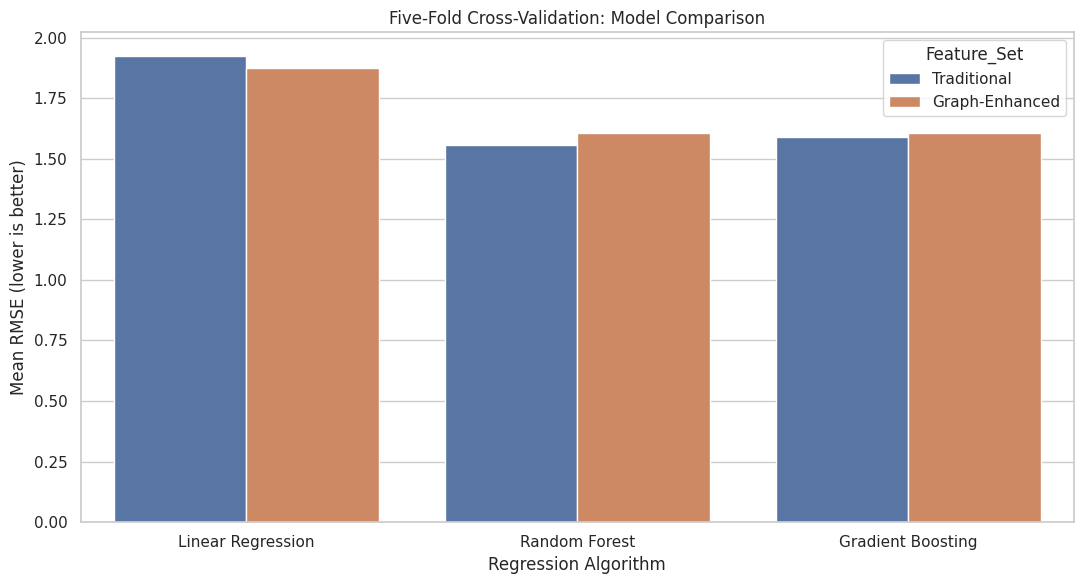

Saved: final_model_comparison.csv


In [112]:

# STEP 12: Final model comparison and validation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Define the two feature sets
traditional_features = [
    "age", "studytime", "failures", "absences", "G1", "G2"
]

graph_features = traditional_features + [
    "degree_centrality",
    "closeness_centrality",
    "betweenness_centrality",
    "eigenvector_centrality",
    "pagerank",
    "community"
]

# Check required columns
required = graph_features + ["G3"]
missing = [c for c in required if c not in ml_df.columns]

if missing:
    raise ValueError(
        f"Missing columns in ml_df: {missing}. "
        "Check the graph-feature merge before continuing."
    )

data = ml_df[required].copy()
data = data.dropna(subset=["G3"])

# 2. Use one identical split for all six experiments
train_df, test_df = train_test_split(
    data, test_size=0.20, random_state=42
)

y_train = train_df["G3"]
y_test = test_df["G3"]

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05,
        max_depth=2, random_state=42
    )
}

feature_sets = {
    "Traditional": traditional_features,
    "Graph-Enhanced": graph_features
}

results = []
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Train, test and cross-validate each model
for feature_type, features in feature_sets.items():
    for model_name, estimator in models.items():

        categorical = (
            ["community"] if "community" in features else []
        )
        numeric = [c for c in features if c not in categorical]

        transformers = [
            ("numeric", SimpleImputer(strategy="median"), numeric)
        ]

        if categorical:
            transformers.append((
                "categorical",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))
                ]),
                categorical
            ))

        prep = ColumnTransformer(transformers=transformers)

        pipeline = Pipeline([
            ("preprocessing", prep),
            ("model", estimator)
        ])

        pipeline.fit(train_df[features], y_train)
        predictions = pipeline.predict(test_df[features])

        cv_results = cross_validate(
            pipeline,
            data[features],
            data["G3"],
            cv=cv,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            n_jobs=1
        )

        results.append({
            "Model": model_name,
            "Feature_Set": feature_type,
            "Test_RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "Test_MAE": mean_absolute_error(y_test, predictions),
            "Test_R2": r2_score(y_test, predictions),
            "CV_RMSE": -cv_results["test_rmse"].mean(),
            "CV_MAE": -cv_results["test_mae"].mean(),
            "CV_R2": cv_results["test_r2"].mean()
        })

comparison_final = pd.DataFrame(results).round(4)

print("FINAL MODEL COMPARISON")
display(
    comparison_final.sort_values("CV_RMSE")
)

comparison_final.to_csv(
    "final_model_comparison.csv", index=False
)

# 4. Visualize cross-validation RMSE
plt.figure(figsize=(11, 6))
sns.barplot(
    data=comparison_final,
    x="Model", y="CV_RMSE", hue="Feature_Set"
)
plt.title("Five-Fold Cross-Validation: Model Comparison")
plt.ylabel("Mean RMSE (lower is better)")
plt.xlabel("Regression Algorithm")
plt.tight_layout()
plt.show()

print("Saved: final_model_comparison.csv")

In [113]:

# STEP 13: Package project results for submission

import os
import zipfile
from google.colab import files

# Save the final comparison
comparison_final.to_csv("final_model_comparison.csv", index=False)

# Save graph metrics and community assignments
centrality_df.to_csv("student_graph_analysis.csv", index=False)

# Save community summary if available
if "community_dashboard" in globals():
    community_dashboard.to_csv("community_summary.csv")

# Save feature importance if available
if "clean_feature_importance" in globals():
    clean_feature_importance.to_csv(
        "feature_importance.csv", index=False
    )

# Package existing project outputs
files_to_package = [
    "final_model_comparison.csv",
    "student_graph_analysis.csv",
    "community_summary.csv",
    "feature_importance.csv",
    "student_similarity_network.html"
]

with zipfile.ZipFile(
    "Graph_Student_Performance_Results.zip", "w"
) as archive:
    for filename in files_to_package:
        if os.path.exists(filename):
            archive.write(filename)

print("Project result files:")
for filename in files_to_package:
    if os.path.exists(filename):
        print("✓", filename)

files.download("Graph_Student_Performance_Results.zip")


Project result files:
✓ final_model_comparison.csv
✓ student_graph_analysis.csv
✓ community_summary.csv
✓ feature_importance.csv
✓ student_similarity_network.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>